# 03 — Penetapan Konfigurasi Fine-Tuning LoRA — FINAL V7
## Controlled Target-First Sequential Search + Checkpoint Selection by chrF++

Notebook ini adalah versi final untuk penetapan konfigurasi LoRA Bahasa Duri → Indonesia.

### Prinsip utama
Pencarian dilakukan **dalam satu notebook**, tetapi tetap bertahap agar setiap keputusan dapat diaudit.

Urutan final:

1. **Stage A — Target Modules (controlled comparison)**
   - `L1`: `q_proj, v_proj`
   - `L2`: `q_proj, k_proj, v_proj, o_proj`
   - `L3`: `q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj`
   - Semua kandidat memakai parameter yang sama:
     - `r = 16`
     - `alpha = 32`
     - `learning_rate = 1e-4`
     - `dropout = 0.05`

2. **Stage B — Rank**
   - target module = pemenang Stage A
   - `r ∈ {4, 8, 16}`
   - `alpha = 2 × r` agar `alpha/r = 2` tetap konstan
   - `learning_rate = 1e-4`
   - `dropout = 0.05`

3. **Stage C — Learning Rate**
   - target + rank/alpha = hasil Stage A–B
   - `learning_rate ∈ {5e-5, 1e-4, 2e-4}`
   - `dropout = 0.05`

4. **Stage D — LoRA Dropout**
   - target + rank/alpha + learning rate = hasil Stage A–C
   - `dropout ∈ {0.00, 0.05, 0.10}`

5. **Final Lock**
   - adapter dan konfigurasi pemenang dikunci untuk inferensi test.

Karena trial yang identik digunakan ulang berdasarkan fingerprint konfigurasi, pipeline ini membutuhkan **maksimal 9 training unik**, bukan Cartesian grid penuh.

### Parameter yang dikunci
- Backbone: `meta-llama/Llama-3.1-8B-Instruct`
- BF16, **tanpa kuantisasi bobot base model** → LoRA, bukan QLoRA
- Train: 417 pasangan / 44 conversation
- Validation: 53 pasangan / 3 conversation
- `test.csv`: hanya dicek keberadaannya; **isinya tidak dibaca**
- Batch size/device: 1
- Gradient accumulation: 8
- Effective batch: 8
- Scheduler: linear
- Warmup ratio: 0.05
- Weight decay: 0
- Max grad norm: 1
- Epoch: 4 penuh
- Seed training: 42
- Maximum sequence length: 640
- Assistant-only loss
- Validation generation: greedy/deterministik

### Pemilihan checkpoint
Setiap trial dilatih 4 epoch penuh dan checkpoint disimpan pada setiap akhir epoch.
Semua checkpoint dievaluasi pada 53 data validation.

Checkpoint representatif suatu trial dipilih dengan urutan:
1. **chrF++ tertinggi**
2. BLEU tertinggi
3. validation loss terendah
4. epoch lebih awal jika seluruh nilai di atas sama

Kandidat pada setiap stage dibandingkan dengan urutan:
1. **chrF++ tertinggi**
2. BLEU tertinggi
3. validation loss checkpoint terpilih lebih rendah
4. parameter trainable lebih sedikit

Validation loss tetap disimpan sebagai diagnostik konvergensi/overfitting, tetapi tidak otomatis menjadi ukuran kualitas terjemahan.

### Batas klaim
Hasil notebook ini adalah **konfigurasi terbaik di antara jalur pencarian bertahap yang diuji pada validation**, bukan global optimum seluruh ruang LoRA.


### Perbaikan FINAL V7
Audit tokenizer pada dataset final menemukan satu sampel train (`C28_T04_B2`)
sepanjang **599 token** setelah format chat Llama diterapkan. Karena itu,
batas 512 pada V6 tidak valid untuk dataset final.

V7 menetapkan **MAX_SEQUENCE_LENGTH = 640**:
- cukup untuk panjang maksimum teramati 599 token;
- tidak melakukan truncation pada source maupun reference;
- tetap dibuat konstan untuk seluruh kandidat LoRA;
- 640 merupakan kelipatan 8 sehingga konsisten dengan padding collator;
- data uji tetap tidak digunakan pada pemilihan konfigurasi.


## Dasar metodologis

Notebook mempertahankan tiga cakupan target module penelitian:

- **L1** — `q_proj, v_proj`
- **L2** — seluruh proyeksi attention
- **L3** — attention + feed-forward

Perbandingan L1/L2/L3 dilakukan terlebih dahulu dalam kondisi terkontrol agar perbedaan Stage A dapat diinterpretasikan sebagai pengaruh **cakupan target module**. Setelah target module dipilih, kapasitas adapter (`r`), learning rate, dan dropout ditetapkan secara bertahap pada target yang sudah terkunci.

Ruang pencarian rank, learning rate, dan dropout adalah ruang pencarian eksperimen Bahasa Duri–Indonesia. Nilai-nilai tersebut tidak diklaim sebagai nilai universal atau global optimum LoRA.


## 1. Instalasi dependensi


In [1]:
# ============================================================
# DEPENDENSI — Vast.ai / VS Code Remote SSH
# ============================================================
# PyTorch/CUDA tidak diinstal ulang.

%pip -q install -U --upgrade-strategy only-if-needed \
    "transformers==4.48.1" \
    "accelerate==1.2.1" \
    "huggingface_hub==0.27.1" \
    "peft==0.14.0" \
    "bitsandbytes==0.48.1" \
    "sacrebleu==2.5.1" \
    "sentencepiece==0.2.0" \
    "protobuf>=4.25,<6" \
    "numpy>=1.26,<3" \
    "pandas>=2.0,<3" \
    "matplotlib>=3.9,<4" \
    "packaging>=24,<26" \
    "tqdm>=4.66,<5" \
    "psutil>=7,<8"

print("Dependensi selesai.")
print("Jika instalasi benar-benar mengubah paket dan kernel meminta restart, restart kernel lalu mulai dari Section 2.")


Note: you may need to restart the kernel to use updated packages.
Dependensi selesai.
Jika instalasi benar-benar mengubah paket dan kernel meminta restart, restart kernel lalu mulai dari Section 2.


## 2. Environment, autentikasi, dan lock backbone


In [3]:
# ============================================================
# ENVIRONMENT + PREFLIGHT
# ============================================================
from __future__ import annotations

import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import gc
import re
import json
import time
import math
import random
import hashlib
import traceback
import shutil
import importlib.metadata as importlib_metadata

from pathlib import Path
from datetime import datetime, timezone
from typing import Any

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from packaging.version import Version
from tqdm.auto import tqdm
from huggingface_hub import get_token, HfApi
from sacrebleu.metrics import BLEU, CHRF

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

from peft import (
    LoraConfig,
    PeftModel,
    TaskType,
    get_peft_model,
)

EXPECTED_VERSIONS = {
    "transformers": "4.48.1",
    "peft": "0.14.0",
    "bitsandbytes": "0.48.1",
}

for package_name, expected_version in EXPECTED_VERSIONS.items():
    actual = importlib_metadata.version(package_name)
    if Version(actual) != Version(expected_version):
        raise RuntimeError(
            f"{package_name}={actual}, tetapi notebook mengunci {expected_version}. "
            "Jalankan Section 1, restart kernel bila diminta, kemudian mulai dari Section 2."
        )

PROJECT_ROOT = Path(
    os.getenv(
        "SKRIPSI_PROJECT_ROOT",
        "/workspace/10122233_CikitaMeydilvira_Skripsi",
    )
).expanduser().resolve()

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"PROJECT_ROOT tidak ditemukan: {PROJECT_ROOT}"
    )

HF_HOME = Path(
    os.getenv(
        "HF_HOME",
        "/workspace/.hf_home",
    )
).expanduser().resolve()

HF_HOME.mkdir(
    parents=True,
    exist_ok=True,
)

os.environ["HF_HOME"] = str(HF_HOME)

DEVICE_INDEX = 0

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA tidak tersedia."
    )

torch.cuda.set_device(
    DEVICE_INDEX
)

if not torch.cuda.is_bf16_supported():
    raise RuntimeError(
        "GPU tidak mendukung BF16. "
        "Notebook ini tidak memiliki fallback FP16/QLoRA."
    )


DTYPE = torch.bfloat16

# ------------------------------------------------------------
# GPU preflight awal.
# Training helper juga mengecek VRAM kembali pada setiap trial.
# ------------------------------------------------------------
gc.collect()
torch.cuda.empty_cache()

_initial_free_b, _initial_total_b = torch.cuda.mem_get_info(DEVICE_INDEX)
_initial_free_gib = _initial_free_b / (1024 ** 3)
_initial_total_gib = _initial_total_b / (1024 ** 3)

print(
    "GPU preflight  :",
    f"{_initial_free_gib:.2f} GiB free / {_initial_total_gib:.2f} GiB total",
)

if _initial_free_gib < 20.0:
    raise RuntimeError(
        f"VRAM bebas hanya {_initial_free_gib:.2f} GiB. "
        "Shutdown kernel 02A/02B atau proses GPU lain sebelum menjalankan 03. "
        "Notebook LoRA memerlukan GPU hampir kosong pada awal trial."
    )

HF_TOKEN = (
    get_token()
    or os.getenv("HF_TOKEN", "").strip()
    or None
)

if not HF_TOKEN:
    raise RuntimeError(
        "Token Hugging Face tidak ditemukan. "
        "Jalankan `hf auth login` di terminal Vast.ai."
    )

EXPECTED_MODEL_ID = (
    "meta-llama/Llama-3.1-8B-Instruct"
)


def resolve_selected_model_id() -> str:

    env_value = os.getenv(
        "SELECTED_TRANSLATOR_MODEL",
        "",
    ).strip()

    if env_value:
        return env_value

    cfg_path = (
        PROJECT_ROOT
        / "Config"
        / "selected_backbone.json"
    )

    if cfg_path.exists():

        with open(
            cfg_path,
            "r",
            encoding="utf-8",
        ) as f:

            obj = json.load(f)

        candidate = str(
            obj.get(
                "model_id",
                "",
            )
        ).strip()

        if candidate:
            return candidate

    return EXPECTED_MODEL_ID


MODEL_ID = resolve_selected_model_id()

if MODEL_ID != EXPECTED_MODEL_ID:
    raise RuntimeError(
        f"Backbone eksperimen utama harus {EXPECTED_MODEL_ID}, "
        f"tetapi ditemukan {MODEL_ID}."
    )

# Validasi akses gated model.
HfApi(
    token=HF_TOKEN
).model_info(
    MODEL_ID
)

TRAINING_SEED = 42

set_seed(
    TRAINING_SEED
)

random.seed(
    TRAINING_SEED
)

np.random.seed(
    TRAINING_SEED
)

torch.manual_seed(
    TRAINING_SEED
)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("HF_HOME      :", HF_HOME)
print("MODEL_ID     :", MODEL_ID)
print("GPU          :", torch.cuda.get_device_name(DEVICE_INDEX))
print(
    "VRAM GiB     :",
    round(
        torch.cuda.get_device_properties(
            DEVICE_INDEX
        ).total_memory / (1024 ** 3),
        2,
    ),
)
print("BF16         :", torch.cuda.is_bf16_supported())
print("Transformers :", importlib_metadata.version("transformers"))
print("PEFT         :", importlib_metadata.version("peft"))
print("bitsandbytes :", importlib_metadata.version("bitsandbytes"))


GPU preflight  : 23.13 GiB free / 23.52 GiB total
PROJECT_ROOT : /workspace/10122233_CikitaMeydilvira_Skripsi
HF_HOME      : /workspace/.hf_home
MODEL_ID     : meta-llama/Llama-3.1-8B-Instruct
GPU          : NVIDIA GeForce RTX 4090
VRAM GiB     : 23.52
BF16         : True
Transformers : 4.48.1
PEFT         : 0.14.0
bitsandbytes : 0.48.1


## 3. Dataset final — train + validation saja


In [4]:
# ============================================================
# DATASET FINAL — HARD LOCK
# Train = 417 / 44 conversations
# Validation = 53 / 3 conversations
# Test = hanya dicek ada, ISI TIDAK DIBACA
# ============================================================

DATASET_DIR = PROJECT_ROOT / "Dataset"
TRAIN_PATH = DATASET_DIR / "train.csv"
VALID_PATH = DATASET_DIR / "validation.csv"
TEST_PATH = DATASET_DIR / "test.csv"

EXPECTED_TRAIN = 417
EXPECTED_VALID = 53
EXPECTED_TRAIN_CONV = 44
EXPECTED_VALID_CONV = 3

REQUIRED_COLUMNS = [
    "row_id",
    "conversation_no",
    "turn_order",
    "duri_text",
    "indonesia_text",
]

for path in [TRAIN_PATH, VALID_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset final tidak ditemukan: {path}"
        )

def load_parallel_split(
    path: Path,
    expected_rows: int,
) -> pd.DataFrame:

    df = pd.read_csv(
        path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    df.columns = [
        str(col).strip()
        for col in df.columns
    ]

    missing = [
        col
        for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{path.name}: kolom wajib hilang: {missing}"
        )

    df = df[
        REQUIRED_COLUMNS
    ].copy()

    for col in REQUIRED_COLUMNS:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
        )

    if len(df) != expected_rows:
        raise ValueError(
            f"{path.name}: diharapkan {expected_rows} baris, "
            f"ditemukan {len(df)}."
        )

    if df["row_id"].eq("").any():
        raise ValueError(
            f"{path.name}: terdapat row_id kosong."
        )

    if df["row_id"].duplicated().any():
        bad = (
            df.loc[
                df["row_id"].duplicated(keep=False),
                "row_id",
            ]
            .tolist()[:10]
        )
        raise ValueError(
            f"{path.name}: row_id duplikat. Contoh: {bad}"
        )

    if (
        df["duri_text"].eq("").any()
        or df["indonesia_text"].eq("").any()
    ):
        raise ValueError(
            f"{path.name}: terdapat teks kosong."
        )

    return df.reset_index(drop=True)

def norm_for_overlap(text: str) -> str:
    return re.sub(
        r"\s+",
        " ",
        str(text).strip().casefold(),
    )

train_df = load_parallel_split(
    TRAIN_PATH,
    EXPECTED_TRAIN,
)

valid_df = load_parallel_split(
    VALID_PATH,
    EXPECTED_VALID,
)

# ------------------------------------------------------------
# Conversation-level split audit
# ------------------------------------------------------------
train_conversations = set(
    train_df["conversation_no"]
)

valid_conversations = set(
    valid_df["conversation_no"]
)

if len(train_conversations) != EXPECTED_TRAIN_CONV:
    raise ValueError(
        f"Train conversation diharapkan {EXPECTED_TRAIN_CONV}, "
        f"ditemukan {len(train_conversations)}."
    )

if len(valid_conversations) != EXPECTED_VALID_CONV:
    raise ValueError(
        f"Validation conversation diharapkan {EXPECTED_VALID_CONV}, "
        f"ditemukan {len(valid_conversations)}."
    )

conversation_overlap = sorted(
    train_conversations
    & valid_conversations
)

if conversation_overlap:
    raise RuntimeError(
        "FATAL: conversation leakage train-validation: "
        f"{conversation_overlap}"
    )

# ------------------------------------------------------------
# Source overlap audit
# Source identik tidak otomatis fatal:
# recurring utterance dapat muncul pada conversation berbeda.
# Exact Duri–Indonesia pair lintas split tetap fatal.
# ------------------------------------------------------------
train_audit = train_df.copy()
valid_audit = valid_df.copy()

train_audit["_src_norm"] = (
    train_audit["duri_text"]
    .map(norm_for_overlap)
)
train_audit["_tgt_norm"] = (
    train_audit["indonesia_text"]
    .map(norm_for_overlap)
)

valid_audit["_src_norm"] = (
    valid_audit["duri_text"]
    .map(norm_for_overlap)
)
valid_audit["_tgt_norm"] = (
    valid_audit["indonesia_text"]
    .map(norm_for_overlap)
)

source_overlap = sorted(
    set(train_audit["_src_norm"])
    & set(valid_audit["_src_norm"])
)

SOURCE_OVERLAP_COUNT = len(
    source_overlap
)

source_overlap_detail = pd.DataFrame()

print(
    "SOURCE OVERLAP TRAIN–VALIDATION :",
    SOURCE_OVERLAP_COUNT,
)

if source_overlap:

    source_overlap_detail = (
        train_audit[
            train_audit["_src_norm"].isin(
                source_overlap
            )
        ][
            [
                "row_id",
                "conversation_no",
                "turn_order",
                "duri_text",
                "indonesia_text",
                "_src_norm",
                "_tgt_norm",
            ]
        ]
        .merge(
            valid_audit[
                valid_audit["_src_norm"].isin(
                    source_overlap
                )
            ][
                [
                    "row_id",
                    "conversation_no",
                    "turn_order",
                    "duri_text",
                    "indonesia_text",
                    "_src_norm",
                    "_tgt_norm",
                ]
            ],
            on="_src_norm",
            how="inner",
            suffixes=("_train", "_valid"),
        )
    )

    source_overlap_detail["target_identik"] = (
        source_overlap_detail[
            "_tgt_norm_train"
        ]
        ==
        source_overlap_detail[
            "_tgt_norm_valid"
        ]
    )

    print(
        "WARNING: ditemukan source Duri identik lintas split. "
        "Ini dicatat sebagai recurring source dan belum otomatis "
        "merupakan exact-pair leakage."
    )

    display(
        source_overlap_detail[
            [
                "_src_norm",
                "row_id_train",
                "conversation_no_train",
                "duri_text_train",
                "indonesia_text_train",
                "row_id_valid",
                "conversation_no_valid",
                "duri_text_valid",
                "indonesia_text_valid",
                "target_identik",
            ]
        ]
    )
else:
    print(
        "OK: tidak ada source identik train-validation."
    )

train_pairs = set(
    zip(
        train_audit["_src_norm"],
        train_audit["_tgt_norm"],
    )
)

valid_pairs = set(
    zip(
        valid_audit["_src_norm"],
        valid_audit["_tgt_norm"],
    )
)

exact_pair_overlap = sorted(
    train_pairs
    & valid_pairs
)

EXACT_PAIR_OVERLAP_COUNT = len(
    exact_pair_overlap
)

print(
    "EXACT PAIR OVERLAP TRAIN–VALIDATION :",
    EXACT_PAIR_OVERLAP_COUNT,
)

if exact_pair_overlap:

    if not source_overlap_detail.empty:

        exact_detail = (
            source_overlap_detail[
                source_overlap_detail[
                    "target_identik"
                ]
            ]
            .copy()
        )

        if not exact_detail.empty:
            display(
                exact_detail[
                    [
                        "_src_norm",
                        "row_id_train",
                        "conversation_no_train",
                        "indonesia_text_train",
                        "row_id_valid",
                        "conversation_no_valid",
                        "indonesia_text_valid",
                    ]
                ]
            )

    raise RuntimeError(
        "FATAL: terdapat pasangan Duri–Indonesia identik "
        "antara train dan validation. Split harus diperbaiki."
    )

print(
    "PASS: tidak ada exact Duri–Indonesia pair "
    "train-validation."
)

if SOURCE_OVERLAP_COUNT > 0:
    print(
        "CATATAN: recurring source lintas conversation akan "
        "dicatat pada output audit. Untuk LoRA tidak ada retrieval "
        "yang dapat difilter; split conversation tetap dipertahankan."
    )

# ------------------------------------------------------------
# Dataset fingerprint
# ------------------------------------------------------------
def dataset_fingerprint() -> str:

    h = hashlib.sha256()

    for split_name, df in [
        ("train", train_df),
        ("validation", valid_df),
    ]:

        ordered = df.sort_values(
            "row_id",
            kind="stable",
        )

        for row in ordered.itertuples(
            index=False
        ):

            payload = {
                "split": split_name,
                "row_id": row.row_id,
                "conversation_no": row.conversation_no,
                "turn_order": row.turn_order,
                "duri_text": row.duri_text,
                "indonesia_text": row.indonesia_text,
            }

            h.update(
                (
                    json.dumps(
                        payload,
                        ensure_ascii=False,
                        sort_keys=True,
                        separators=(",", ":"),
                    )
                    + "\n"
                ).encode("utf-8")
            )

    return h.hexdigest()

DATASET_FINGERPRINT = (
    dataset_fingerprint()
)

print()
print("Train path          :", TRAIN_PATH)
print("Validation path     :", VALID_PATH)
print("Train               :", len(train_df), "/", len(train_conversations), "conversation")
print("Validation          :", len(valid_df), "/", len(valid_conversations), "conversation")
print("Test                : TIDAK DIBACA")
print("Dataset fingerprint :", DATASET_FINGERPRINT)


SOURCE OVERLAP TRAIN–VALIDATION : 1


,_src_norm,row_id_train,conversation_no_train,duri_text_train,indonesia_text_train,row_id_valid,conversation_no_valid,duri_text_valid,indonesia_text_valid,target_identik
0,waqdingraka ke undinaq?,C01_T05_A3,1,Waqdingraka ke undinaq?,Bolehkah jika saya ikut?,C40_T03_A2,40,Waqdingraka ke undinaq?,Bolehkah saya ikut?,False


EXACT PAIR OVERLAP TRAIN–VALIDATION : 0
PASS: tidak ada exact Duri–Indonesia pair train-validation.
CATATAN: recurring source lintas conversation akan dicatat pada output audit. Untuk LoRA tidak ada retrieval yang dapat difilter; split conversation tetap dipertahankan.

Train path          : /workspace/10122233_CikitaMeydilvira_Skripsi/Dataset/train.csv
Validation path     : /workspace/10122233_CikitaMeydilvira_Skripsi/Dataset/validation.csv
Train               : 417 / 44 conversation
Validation          : 53 / 3 conversation
Test                : TIDAK DIBACA
Dataset fingerprint : 6c8f3cb81c2dfe100390e26ca33147c8324e90dffa31092ae63c18310ba6fdcc


## 4. Tokenizer, prompt, audit sequence length, dan assistant-only loss


In [5]:
# ============================================================
# TOKENIZER + DATASET SFT
# ============================================================
from torch.utils.data import Dataset

SYSTEM_MESSAGE = (
    "Anda adalah penerjemah bahasa Duri ke bahasa Indonesia."
)

USER_TEMPLATE = (
    "Terjemahkan teks bahasa Duri berikut ke bahasa Indonesia.\n"
    "Keluarkan hanya hasil terjemahan tanpa penjelasan tambahan.\n\n"
    "Bahasa Duri: {duri_text}\n"
    "Bahasa Indonesia:"
)

MAX_SEQUENCE_LENGTH = 640
VALIDATION_MAX_NEW_TOKENS = 128

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN,
    use_fast=True,
    trust_remote_code=False,
    cache_dir=str(HF_HOME),
)

if tokenizer.chat_template is None:
    raise RuntimeError(
        "Tokenizer tidak memiliki chat_template."
    )

if tokenizer.pad_token_id is None:

    if tokenizer.eos_token_id is None:
        raise RuntimeError(
            "Tokenizer tidak memiliki pad_token_id maupun eos_token_id."
        )

    tokenizer.pad_token = (
        tokenizer.eos_token
    )

tokenizer.padding_side = (
    "right"
)


def build_user_messages(
    duri_text: str,
) -> list[dict[str, str]]:

    return [
        {
            "role": "system",
            "content": SYSTEM_MESSAGE,
        },
        {
            "role": "user",
            "content": USER_TEMPLATE.format(
                duri_text=duri_text
            ),
        },
    ]


def build_training_messages(
    duri_text: str,
    indonesia_text: str,
) -> list[dict[str, str]]:

    return (
        build_user_messages(
            duri_text
        )
        + [
            {
                "role": "assistant",
                "content": indonesia_text,
            }
        ]
    )


def encode_sft(
    duri_text: str,
    indonesia_text: str,
) -> dict[str, list[int]]:

    prompt_ids = (
        tokenizer.apply_chat_template(
            build_user_messages(
                duri_text
            ),
            tokenize=True,
            add_generation_prompt=True,
        )
    )

    full_ids = (
        tokenizer.apply_chat_template(
            build_training_messages(
                duri_text,
                indonesia_text,
            ),
            tokenize=True,
            add_generation_prompt=False,
        )
    )

    common = 0

    for prompt_token, full_token in zip(
        prompt_ids,
        full_ids,
    ):

        if prompt_token != full_token:
            break

        common += 1

    if len(full_ids) > MAX_SEQUENCE_LENGTH:
        raise ValueError(
            f"Sampel > {MAX_SEQUENCE_LENGTH} token. "
            f"Duri={duri_text!r}, panjang={len(full_ids)}"
        )

    labels = (
        [-100] * common
        + list(
            full_ids[
                common:
            ]
        )
    )

    if (
        not labels
        or all(
            token_id == -100
            for token_id in labels
        )
    ):
        raise ValueError(
            "Tidak ada token assistant untuk loss."
        )

    return {
        "input_ids": list(
            full_ids
        ),
        "attention_mask": [
            1
        ] * len(
            full_ids
        ),
        "labels": labels,
    }


# ------------------------------------------------------------
# Audit panjang seluruh train + validation
# ------------------------------------------------------------

length_rows = []

for split_name, data in [
    (
        "train",
        train_df,
    ),
    (
        "validation",
        valid_df,
    ),
]:

    for row in data.itertuples(
        index=False
    ):

        full_ids = (
            tokenizer.apply_chat_template(
                build_training_messages(
                    row.duri_text,
                    row.indonesia_text,
                ),
                tokenize=True,
                add_generation_prompt=False,
            )
        )

        length_rows.append(
            {
                "split": split_name,
                "row_id": row.row_id,
                "tokens": len(
                    full_ids
                ),
            }
        )

length_audit_df = pd.DataFrame(
    length_rows
)

print(
    "Sequence min  :",
    int(
        length_audit_df[
            "tokens"
        ].min()
    ),
)

print(
    "Sequence mean :",
    round(
        float(
            length_audit_df[
                "tokens"
            ].mean()
        ),
        2,
    ),
)

print(
    "Sequence max  :",
    int(
        length_audit_df[
            "tokens"
        ].max()
    ),
)

too_long = (
    length_audit_df[
        "tokens"
    ]
    > MAX_SEQUENCE_LENGTH
)

print(
    f">{MAX_SEQUENCE_LENGTH:<12}:",
    int(
        too_long.sum()
    ),
)


# Informasi baris terpanjang untuk audit/reproducibility.
_longest_rows = (
    length_audit_df
    .sort_values(
        ["tokens", "split", "row_id"],
        ascending=[False, True, True],
        kind="stable",
    )
    .head(10)
)

print("\\n10 sequence terpanjang:")
display(_longest_rows)

if too_long.any():

    too_long_df = (
        length_audit_df[
            too_long
        ]
        .sort_values(
            "tokens",
            ascending=False,
        )
        .copy()
    )

    display(
        too_long_df
    )

    observed_max = int(
        too_long_df[
            "tokens"
        ].max()
    )

    raise ValueError(
        "Ada sampel yang melebihi MAX_SEQUENCE_LENGTH="
        f"{MAX_SEQUENCE_LENGTH}. Panjang maksimum teramati="
        f"{observed_max}. Notebook sengaja tidak melakukan truncation "
        "source/reference secara diam-diam. Naikkan batas secara eksplisit "
        "dan gunakan nilai yang sama untuk seluruh trial."
    )

print(
    "PASS sequence-length audit: seluruh train+validation <=",
    MAX_SEQUENCE_LENGTH,
    "token; tidak ada truncation."
)


class SFTDataset(
    Dataset
):

    def __init__(
        self,
        dataframe: pd.DataFrame,
        split_name: str,
    ) -> None:

        self.items = [
            encode_sft(
                row.duri_text,
                row.indonesia_text,
            )
            for row in tqdm(
                dataframe.itertuples(
                    index=False
                ),
                total=len(
                    dataframe
                ),
                desc=(
                    f"Tokenisasi {split_name}"
                ),
            )
        ]

    def __len__(
        self,
    ) -> int:

        return len(
            self.items
        )

    def __getitem__(
        self,
        index: int,
    ) -> dict[str, list[int]]:

        return self.items[
            index
        ]


class AssistantOnlyCollator:

    def __init__(
        self,
        pad_token_id: int,
        pad_to_multiple_of: int = 8,
    ) -> None:

        self.pad_token_id = int(
            pad_token_id
        )

        self.pad_to_multiple_of = int(
            pad_to_multiple_of
        )

    def __call__(
        self,
        features: list[
            dict[str, list[int]]
        ],
    ) -> dict[str, torch.Tensor]:

        max_len = max(
            len(
                item[
                    "input_ids"
                ]
            )
            for item in features
        )

        if self.pad_to_multiple_of > 1:

            max_len = (
                (
                    max_len
                    + self.pad_to_multiple_of
                    - 1
                )
                // self.pad_to_multiple_of
                * self.pad_to_multiple_of
            )

        input_ids = []
        attention_masks = []
        labels = []

        for item in features:

            pad = (
                max_len
                - len(
                    item[
                        "input_ids"
                    ]
                )
            )

            input_ids.append(
                item[
                    "input_ids"
                ]
                + [
                    self.pad_token_id
                ] * pad
            )

            attention_masks.append(
                item[
                    "attention_mask"
                ]
                + [
                    0
                ] * pad
            )

            labels.append(
                item[
                    "labels"
                ]
                + [
                    -100
                ] * pad
            )

        return {
            "input_ids": torch.tensor(
                input_ids,
                dtype=torch.long,
            ),
            "attention_mask": torch.tensor(
                attention_masks,
                dtype=torch.long,
            ),
            "labels": torch.tensor(
                labels,
                dtype=torch.long,
            ),
        }


train_dataset = SFTDataset(
    train_df,
    "train",
)

valid_dataset = SFTDataset(
    valid_df,
    "validation",
)

collator = AssistantOnlyCollator(
    tokenizer.pad_token_id
)

print(
    "Dataset tokenized:",
    len(train_dataset),
    len(valid_dataset),
)


Sequence min  : 99
Sequence mean : 128.72
Sequence max  : 599
>640         : 0
\n10 sequence terpanjang:


,split,row_id,tokens
222,train,C28_T04_B2,599
192,train,C24_T06_B3,284
406,train,C49_T04_B2,271
289,train,C36_T10_B5,268
190,train,C24_T04_B2,252
400,train,C48_T08_B4,248
463,validation,C40_T26_B13,247
321,train,C39_T12_B6,216
145,train,C19_T08_B4,213
325,train,C41_T04_B2,213


PASS sequence-length audit: seluruh train+validation <= 640 token; tidak ada truncation.


Tokenisasi train:   0%|          | 0/417 [00:00<?, ?it/s]

Tokenisasi validation:   0%|          | 0/53 [00:00<?, ?it/s]

Dataset tokenized: 417 53


## 5. Ruang pencarian dan protokol training


In [6]:
# ============================================================
# SEARCH SPACE — FINAL V6
# ============================================================

TARGET_MODULE_OPTIONS = {
    "L1": [
        "q_proj",
        "v_proj",
    ],
    "L2": [
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
    ],
    "L3": [
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
}

RANK_VALUES = [
    4,
    8,
    16,
]

LEARNING_RATE_VALUES = [
    5e-5,
    1e-4,
    2e-4,
]

DROPOUT_VALUES = [
    0.00,
    0.05,
    0.10,
]

# ------------------------------------------------------------
# Controlled anchor untuk Stage A
# ------------------------------------------------------------
BASE_RANK = 16
BASE_ALPHA = 32
BASE_LEARNING_RATE = 1e-4
BASE_DROPOUT = 0.05

# Setelah Stage A, alpha mengikuti rank:
# alpha/r = 2
ALPHA_MULTIPLIER = 2

LR_SCHEDULER_TYPE = "linear"
WARMUP_RATIO = 0.05
WEIGHT_DECAY = 0.0
MAX_GRAD_NORM = 1.0

PER_DEVICE_TRAIN_BATCH_SIZE = 1
PER_DEVICE_EVAL_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8

MAX_EPOCHS = 4

# Semua checkpoint akhir epoch disimpan agar setiap epoch
# dapat dievaluasi dengan chrF++/BLEU.
SAVE_TOTAL_LIMIT = MAX_EPOCHS

OPTIMIZER = "paged_adamw_8bit"

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "Hasil"
    / "config_selection"
    / "lora_target_first_v7"
)

TRIAL_ROOT = (
    OUTPUT_ROOT
    / "trials"
)

STAGE_ROOT = (
    OUTPUT_ROOT
    / "stages"
)

FIGURE_ROOT = (
    OUTPUT_ROOT
    / "figures_bab4"
)

for directory in [
    OUTPUT_ROOT,
    TRIAL_ROOT,
    STAGE_ROOT,
    FIGURE_ROOT,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

# Canonical outputs
CANONICAL_SELECTED_DIR = (
    PROJECT_ROOT
    / "Hasil"
    / "config_selection"
    / "lora"
)

CANONICAL_SELECTED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CANONICAL_SELECTED_PATH = (
    CANONICAL_SELECTED_DIR
    / "selected_lora_config.json"
)

CONFIG_LOCK_PATH = (
    PROJECT_ROOT
    / "Config"
    / "lora_locked_config.json"
)

LOCKED_ADAPTER_DIR = (
    PROJECT_ROOT
    / "Artifacts"
    / "lora_locked_adapter"
)

CHECKPOINT_SELECTION_RULE = (
    "complete validation -> chrF++ descending; "
    "BLEU descending; validation loss ascending; "
    "epoch ascending"
)

STAGE_SELECTION_RULE = (
    "complete validation -> chrF++ descending; "
    "BLEU descending; selected checkpoint validation loss ascending; "
    "trainable parameters ascending"
)

print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("Stage A     : target_modules L1/L2/L3, fixed r=16 alpha=32 LR=1e-4 dropout=0.05")
print("Stage B     : rank", RANK_VALUES)
print("Stage C LR  :", LEARNING_RATE_VALUES)
print("Stage D drop:", DROPOUT_VALUES)
print("Epoch       :", MAX_EPOCHS)
print("Early stop  : TIDAK DIGUNAKAN")
print("Checkpoint  :", CHECKPOINT_SELECTION_RULE)


OUTPUT_ROOT : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7
Stage A     : target_modules L1/L2/L3, fixed r=16 alpha=32 LR=1e-4 dropout=0.05
Stage B     : rank [4, 8, 16]
Stage C LR  : [5e-05, 0.0001, 0.0002]
Stage D drop: [0.0, 0.05, 0.1]
Epoch       : 4
Early stop  : TIDAK DIGUNAKAN
Checkpoint  : complete validation -> chrF++ descending; BLEU descending; validation loss ascending; epoch ascending


## 6. Helper training, checkpoint evaluation, resume, dan cleanup GPU

### Logika V5

Satu trial:

```text
train 4 epoch
    ↓
checkpoint epoch 1
checkpoint epoch 2
checkpoint epoch 3
checkpoint epoch 4
    ↓
masing-masing checkpoint:
generasi 53 validation secara deterministik
    ↓
chrF++ + BLEU + eval loss
    ↓
pilih checkpoint terbaik berdasarkan chrF++
```

`eval_loss` tetap dicatat setiap akhir epoch tetapi **tidak** menjadi kriteria utama checkpoint.

Evaluasi checkpoint bersifat resume-safe: jika metrik satu checkpoint sudah tersimpan, checkpoint tersebut tidak digenerasi ulang.


In [7]:
# ============================================================
# HELPER TRAINING + CHECKPOINT SELECTION
# ============================================================

def gpu_sync() -> None:

    if torch.cuda.is_available():
        torch.cuda.synchronize(
            DEVICE_INDEX
        )


def clear_gpu_strong() -> None:

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        try:
            torch.cuda.ipc_collect()
        except Exception:
            pass

        try:
            torch.cuda.synchronize(
                DEVICE_INDEX
            )
        except Exception:
            pass

    gc.collect()


def free_vram_gib() -> float:

    clear_gpu_strong()

    free_bytes, _ = (
        torch.cuda.mem_get_info(
            DEVICE_INDEX
        )
    )

    return float(
        free_bytes
        / (1024 ** 3)
    )


def clean_translation_output(
    text: str,
) -> str:

    value = str(
        text
    ).strip()

    prefixes = [
        "Bahasa Indonesia:",
        "Terjemahan:",
        "Jawaban:",
    ]

    changed = True

    while changed:

        changed = False

        for prefix in prefixes:

            if value.lower().startswith(
                prefix.lower()
            ):

                value = value[
                    len(prefix):
                ].strip()

                changed = True

    return value.strip()


def generate_validation_one(
    model,
    duri_text: str,
) -> str:

    messages = build_user_messages(
        duri_text
    )

    encoded = (
        tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True,
        )
    )

    encoded = {
        key: value.to(
            model.device
        )
        for key, value in encoded.items()
    }

    terminators = []

    if tokenizer.eos_token_id is not None:

        terminators.append(
            int(
                tokenizer.eos_token_id
            )
        )

    eot = (
        tokenizer.convert_tokens_to_ids(
            "<|eot_id|>"
        )
    )

    if (
        isinstance(
            eot,
            int,
        )
        and eot >= 0
        and eot
        != tokenizer.unk_token_id
        and eot
        not in terminators
    ):

        terminators.append(
            eot
        )

    generation_kwargs = {
        "max_new_tokens":
            VALIDATION_MAX_NEW_TOKENS,
        "do_sample":
            False,
        "num_beams":
            1,
        "repetition_penalty":
            1.0,
        "use_cache":
            True,
        "pad_token_id":
            tokenizer.pad_token_id,
    }

    if terminators:

        generation_kwargs[
            "eos_token_id"
        ] = terminators

    with torch.inference_mode():

        outputs = model.generate(
            **encoded,
            **generation_kwargs,
        )

    prompt_tokens = int(
        encoded[
            "input_ids"
        ].shape[
            -1
        ]
    )

    generated = outputs[
        0,
        prompt_tokens:
    ]

    decoded = tokenizer.decode(
        generated,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return clean_translation_output(
        decoded
    )


def deterministic_validation(
    model,
    evaluation_id: str,
) -> tuple[
    pd.DataFrame,
    float,
    float,
]:

    model.eval()
    model.config.use_cache = True

    try:
        model.gradient_checkpointing_disable()
    except Exception:
        pass

    records = []

    for row in tqdm(
        valid_df.itertuples(
            index=False
        ),
        total=len(
            valid_df
        ),
        desc=(
            f"Validation {evaluation_id}"
        ),
    ):

        start = (
            time.perf_counter()
        )

        output = (
            generate_validation_one(
                model,
                row.duri_text,
            )
        )

        elapsed = (
            time.perf_counter()
            - start
        )

        if not output:

            raise RuntimeError(
                f"{evaluation_id}: output kosong "
                f"untuk row_id={row.row_id}"
            )

        records.append(
            {
                "evaluation_id":
                    evaluation_id,
                "row_id":
                    row.row_id,
                "source_text":
                    row.duri_text,
                "reference_text":
                    row.indonesia_text,
                "selected_output":
                    output,
                "generation_time_seconds":
                    elapsed,
            }
        )

    pred_df = pd.DataFrame(
        records
    )

    hypotheses = (
        pred_df[
            "selected_output"
        ].tolist()
    )

    references = (
        pred_df[
            "reference_text"
        ].tolist()
    )

    bleu = float(
        BLEU(
            tokenize="13a"
        ).corpus_score(
            hypotheses,
            [
                references
            ],
        ).score
    )

    chrfpp = float(
        CHRF(
            word_order=2
        ).corpus_score(
            hypotheses,
            [
                references
            ],
        ).score
    )

    return (
        pred_df,
        bleu,
        chrfpp,
    )


def canonical_trial_payload(
    *,
    rank: int,
    target_label: str,
    learning_rate: float,
    dropout: float,
) -> dict[str, Any]:

    if target_label not in TARGET_MODULE_OPTIONS:

        raise KeyError(
            f"Target label tidak dikenal: {target_label}"
        )

    alpha = int(
        ALPHA_MULTIPLIER
        * rank
    )

    return {
        "model_id":
            MODEL_ID,
        "dataset_fingerprint":
            DATASET_FINGERPRINT,
        "source_overlap_count":
            int(SOURCE_OVERLAP_COUNT),
        "exact_pair_overlap_count":
            int(EXACT_PAIR_OVERLAP_COUNT),
        "test_read":
            False,
        "prompt_protocol":
            "llama_chat_system_plus_user_translation_v6",
        "rank":
            int(
                rank
            ),
        "alpha":
            alpha,
        "alpha_over_r":
            float(
                alpha
                / rank
            ),
        "dropout":
            float(
                dropout
            ),
        "target_label":
            target_label,
        "target_modules":
            list(
                TARGET_MODULE_OPTIONS[
                    target_label
                ]
            ),
        "learning_rate":
            float(
                learning_rate
            ),
        "lr_scheduler_type":
            LR_SCHEDULER_TYPE,
        "warmup_ratio":
            float(
                WARMUP_RATIO
            ),
        "weight_decay":
            float(
                WEIGHT_DECAY
            ),
        "max_grad_norm":
            float(
                MAX_GRAD_NORM
            ),
        "per_device_train_batch_size":
            int(
                PER_DEVICE_TRAIN_BATCH_SIZE
            ),
        "gradient_accumulation_steps":
            int(
                GRADIENT_ACCUMULATION_STEPS
            ),
        "max_epochs":
            int(
                MAX_EPOCHS
            ),
        "early_stopping":
            False,
        "checkpoint_selection_rule":
            CHECKPOINT_SELECTION_RULE,
        "max_sequence_length":
            int(
                MAX_SEQUENCE_LENGTH
            ),
        "training_seed":
            int(
                TRAINING_SEED
            ),
        "train_rows":
            int(
                len(
                    train_df
                )
            ),
        "validation_rows":
            int(
                len(
                    valid_df
                )
            ),
    }


def payload_fingerprint(
    payload: dict[str, Any],
) -> str:

    raw = json.dumps(
        payload,
        ensure_ascii=False,
        sort_keys=True,
        separators=(
            ",",
            ":",
        ),
    ).encode(
        "utf-8"
    )

    return hashlib.sha256(
        raw
    ).hexdigest()[
        :16
    ]


def load_lora_training_model(
    payload: dict[str, Any],
):

    clear_gpu_strong()

    free_before = (
        free_vram_gib()
    )

    print(
        "VRAM free sebelum load:",
        f"{free_before:.2f} GiB",
    )

    if free_before < 20.0:

        raise RuntimeError(
            f"VRAM bebas hanya {free_before:.2f} GiB. "
            "Kemungkinan model/proses GPU lama masih tertahan. "
            "Restart kernel atau hentikan proses GPU lain."
        )

    base = (
        AutoModelForCausalLM
        .from_pretrained(
            MODEL_ID,
            token=HF_TOKEN,
            torch_dtype=DTYPE,
            device_map={
                "": DEVICE_INDEX
            },
            low_cpu_mem_usage=True,
            trust_remote_code=False,
            cache_dir=str(
                HF_HOME
            ),
        )
    )

    if (
        bool(
            getattr(
                base,
                "is_loaded_in_4bit",
                False,
            )
        )
        or bool(
            getattr(
                base,
                "is_loaded_in_8bit",
                False,
            )
        )
    ):

        raise RuntimeError(
            "Base model terkuantisasi. "
            "Eksperimen harus LoRA BF16, bukan QLoRA."
        )

    target_modules = (
        payload[
            "target_modules"
        ]
    )

    missing_modules = [
        module_name
        for module_name in target_modules
        if not any(
            name.endswith(
                module_name
            )
            for name, _ in base.named_modules()
        )
    ]

    if missing_modules:

        raise RuntimeError(
            "Target module tidak ditemukan: "
            f"{missing_modules}"
        )

    base.config.use_cache = False

    base.gradient_checkpointing_enable()

    base.enable_input_require_grads()

    lora_config = LoraConfig(
        r=int(
            payload[
                "rank"
            ]
        ),
        lora_alpha=int(
            payload[
                "alpha"
            ]
        ),
        lora_dropout=float(
            payload[
                "dropout"
            ]
        ),
        bias="none",
        task_type=(
            TaskType.CAUSAL_LM
        ),
        target_modules=(
            target_modules
        ),
    )

    model = get_peft_model(
        base,
        lora_config,
    )

    trainable = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    total = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    unexpected = [
        name
        for name, parameter
        in model.named_parameters()
        if (
            parameter.requires_grad
            and "lora_" not in name.lower()
        )
    ]

    if unexpected:

        raise RuntimeError(
            "Parameter non-LoRA ikut trainable. "
            f"Contoh: {unexpected[:10]}"
        )

    print(
        f"Trainable: {trainable:,}/{total:,} "
        f"({100 * trainable / total:.4f}%)"
    )

    return (
        model,
        trainable,
        total,
    )


def list_epoch_checkpoints(
    trainer_dir: Path,
) -> list[Path]:

    checkpoints = []

    for path in trainer_dir.glob(
        "checkpoint-*"
    ):

        if not path.is_dir():
            continue

        match = re.fullmatch(
            r"checkpoint-(\d+)",
            path.name,
        )

        if not match:
            continue

        checkpoints.append(
            (
                int(
                    match.group(
                        1
                    )
                ),
                path,
            )
        )

    checkpoints.sort(
        key=lambda item: item[
            0
        ]
    )

    return [
        path
        for _, path in checkpoints
    ]


def eval_loss_for_step(
    history_df: pd.DataFrame,
    step: int,
) -> tuple[
    float,
    float | None,
]:

    if (
        "eval_loss"
        not in history_df.columns
        or "step"
        not in history_df.columns
    ):

        raise RuntimeError(
            "training_log tidak memiliki eval_loss/step."
        )

    eval_rows = history_df[
        history_df[
            "eval_loss"
        ].notna()
    ].copy()

    matched = eval_rows[
        pd.to_numeric(
            eval_rows[
                "step"
            ],
            errors="coerce",
        )
        == int(
            step
        )
    ]

    if matched.empty:

        raise RuntimeError(
            f"eval_loss untuk checkpoint step={step} "
            "tidak ditemukan."
        )

    row = matched.iloc[
        -1
    ]

    eval_loss = float(
        row[
            "eval_loss"
        ]
    )

    epoch = None

    if (
        "epoch"
        in matched.columns
        and pd.notna(
            row[
                "epoch"
            ]
        )
    ):

        epoch = float(
            row[
                "epoch"
            ]
        )

    return (
        eval_loss,
        epoch,
    )


def load_checkpoint_for_inference(
    checkpoint_path: Path,
):

    clear_gpu_strong()

    free_before = (
        free_vram_gib()
    )

    if free_before < 20.0:

        raise RuntimeError(
            f"VRAM bebas hanya {free_before:.2f} GiB "
            "sebelum evaluasi checkpoint."
        )

    base = (
        AutoModelForCausalLM
        .from_pretrained(
            MODEL_ID,
            token=HF_TOKEN,
            torch_dtype=DTYPE,
            device_map={
                "": DEVICE_INDEX
            },
            low_cpu_mem_usage=True,
            trust_remote_code=False,
            cache_dir=str(
                HF_HOME
            ),
        )
    )

    if (
        bool(
            getattr(
                base,
                "is_loaded_in_4bit",
                False,
            )
        )
        or bool(
            getattr(
                base,
                "is_loaded_in_8bit",
                False,
            )
        )
    ):

        raise RuntimeError(
            "Base model evaluasi terkuantisasi."
        )

    model = PeftModel.from_pretrained(
        base,
        str(
            checkpoint_path
        ),
        is_trainable=False,
    )

    model.eval()
    model.config.use_cache = True

    try:
        model.gradient_checkpointing_disable()
    except Exception:
        pass

    return model


def evaluate_checkpoint(
    *,
    trial_id: str,
    checkpoint_path: Path,
    history_df: pd.DataFrame,
    checkpoint_eval_root: Path,
) -> dict[str, Any]:

    match = re.fullmatch(
        r"checkpoint-(\d+)",
        checkpoint_path.name,
    )

    if not match:

        raise ValueError(
            f"Nama checkpoint tidak valid: {checkpoint_path}"
        )

    step = int(
        match.group(
            1
        )
    )

    eval_loss, epoch = (
        eval_loss_for_step(
            history_df,
            step,
        )
    )

    output_dir = (
        checkpoint_eval_root
        / checkpoint_path.name
    )

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    metrics_path = (
        output_dir
        / "metrics.json"
    )

    predictions_path = (
        output_dir
        / "validation_predictions.csv"
    )

    if (
        metrics_path.exists()
        and predictions_path.exists()
    ):

        with open(
            metrics_path,
            "r",
            encoding="utf-8",
        ) as f:

            metrics = json.load(
                f
            )

        print(
            f"Reuse evaluasi "
            f"{trial_id}/{checkpoint_path.name}"
        )

        return metrics

    model = None

    try:

        print(
            "\nEvaluasi:",
            trial_id,
            checkpoint_path.name,
        )

        model = (
            load_checkpoint_for_inference(
                checkpoint_path
            )
        )

        pred_df, bleu, chrfpp = (
            deterministic_validation(
                model,
                (
                    f"{trial_id}_"
                    f"{checkpoint_path.name}"
                ),
            )
        )

        pred_df.to_csv(
            predictions_path,
            index=False,
            encoding="utf-8-sig",
        )

        metrics = {
            "trial_id":
                trial_id,
            "checkpoint_name":
                checkpoint_path.name,
            "checkpoint_path":
                str(
                    checkpoint_path
                ),
            "step":
                int(
                    step
                ),
            "epoch":
                (
                    None
                    if epoch is None
                    else float(
                        epoch
                    )
                ),
            "eval_loss":
                float(
                    eval_loss
                ),
            "validation_chrfpp":
                float(
                    chrfpp
                ),
            "validation_bleu":
                float(
                    bleu
                ),
            "predictions_path":
                str(
                    predictions_path
                ),
            "evaluated_at_utc":
                datetime.now(
                    timezone.utc
                ).isoformat(),
        }

        with open(
            metrics_path,
            "w",
            encoding="utf-8",
        ) as f:

            json.dump(
                metrics,
                f,
                ensure_ascii=False,
                indent=2,
            )

        return metrics

    finally:

        model = None

        clear_gpu_strong()


def select_checkpoint(
    checkpoint_df: pd.DataFrame,
) -> pd.Series:

    if checkpoint_df.empty:

        raise RuntimeError(
            "Tidak ada checkpoint yang dapat dipilih."
        )

    ranked = (
        checkpoint_df
        .sort_values(
            [
                "validation_chrfpp",
                "validation_bleu",
                "eval_loss",
                "epoch",
            ],
            ascending=[
                False,
                False,
                True,
                True,
            ],
            kind="stable",
        )
        .reset_index(
            drop=True
        )
    )

    return ranked.iloc[
        0
    ]


def materialize_selected_adapter(
    *,
    selected_checkpoint: Path,
    selected_adapter_dir: Path,
) -> None:

    if selected_adapter_dir.exists():

        shutil.rmtree(
            selected_adapter_dir
        )

    selected_adapter_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    required_candidates = [
        "adapter_config.json",
        "adapter_model.safetensors",
        "adapter_model.bin",
    ]

    copied = []

    for filename in required_candidates:

        source = (
            selected_checkpoint
            / filename
        )

        if source.exists():

            shutil.copy2(
                source,
                selected_adapter_dir
                / filename,
            )

            copied.append(
                filename
            )

    if (
        "adapter_config.json"
        not in copied
    ):

        raise FileNotFoundError(
            f"adapter_config.json tidak ditemukan "
            f"di {selected_checkpoint}"
        )

    if not (
        (
            selected_adapter_dir
            / "adapter_model.safetensors"
        ).exists()
        or (
            selected_adapter_dir
            / "adapter_model.bin"
        ).exists()
    ):

        raise FileNotFoundError(
            f"Bobot adapter tidak ditemukan "
            f"di {selected_checkpoint}"
        )

    tokenizer.save_pretrained(
        selected_adapter_dir
    )


def run_trial(
    *,
    rank: int,
    target_label: str,
    learning_rate: float,
    dropout: float,
    stage_name: str,
    stage_candidate: str,
) -> dict[str, Any]:

    payload = (
        canonical_trial_payload(
            rank=rank,
            target_label=target_label,
            learning_rate=learning_rate,
            dropout=dropout,
        )
    )

    fingerprint = (
        payload_fingerprint(
            payload
        )
    )

    trial_id = (
        f"trial_{fingerprint}"
    )

    trial_dir = (
        TRIAL_ROOT
        / trial_id
    )

    trial_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    completed_path = (
        trial_dir
        / "completed_summary.json"
    )

    failure_path = (
        trial_dir
        / "failure.json"
    )

    trainer_dir = (
        trial_dir
        / "trainer"
    )

    log_path = (
        trial_dir
        / "training_log.csv"
    )

    checkpoint_eval_root = (
        trial_dir
        / "checkpoint_validation"
    )

    selected_adapter_dir = (
        trial_dir
        / "selected_adapter"
    )

    selected_predictions_path = (
        trial_dir
        / "validation_predictions.csv"
    )

    checkpoint_metrics_path = (
        trial_dir
        / "checkpoint_metrics.csv"
    )

    # --------------------------------------------------------
    # Trial selesai -> reuse
    # --------------------------------------------------------

    if completed_path.exists():

        with open(
            completed_path,
            "r",
            encoding="utf-8",
        ) as f:

            completed = json.load(
                f
            )

        completed_payload = (
            completed.get(
                "payload",
                {}
            )
        )

        if (
            payload_fingerprint(
                completed_payload
            )
            != fingerprint
        ):

            raise RuntimeError(
                f"Summary trial tidak konsisten: {trial_id}"
            )

        print(
            f"{stage_name} / {stage_candidate}: "
            f"reuse {trial_id}"
        )

        result = dict(
            completed
        )

        result[
            "stage_name"
        ] = stage_name

        result[
            "stage_candidate"
        ] = stage_candidate

        return result

    model = None
    trainer = None

    training_seconds = float(
        "nan"
    )

    trainable = None
    total = None
    peak_training_gpu_gib = float(
        "nan"
    )

    try:

        print(
            "\n"
            + "=" * 80
        )

        print(
            f"{stage_name} — {stage_candidate}"
        )

        print(
            trial_id
        )

        print(
            json.dumps(
                payload,
                ensure_ascii=False,
                indent=2,
            )
        )

        # ====================================================
        # PHASE 1 — TRAIN 4 EPOCH
        # ====================================================

        model, trainable, total = (
            load_lora_training_model(
                payload
            )
        )

        torch.cuda.reset_peak_memory_stats(
            DEVICE_INDEX
        )

        training_args = TrainingArguments(
            output_dir=str(
                trainer_dir
            ),
            learning_rate=float(
                payload[
                    "learning_rate"
                ]
            ),
            lr_scheduler_type=(
                LR_SCHEDULER_TYPE
            ),
            warmup_ratio=(
                WARMUP_RATIO
            ),
            weight_decay=(
                WEIGHT_DECAY
            ),
            max_grad_norm=(
                MAX_GRAD_NORM
            ),
            per_device_train_batch_size=(
                PER_DEVICE_TRAIN_BATCH_SIZE
            ),
            per_device_eval_batch_size=(
                PER_DEVICE_EVAL_BATCH_SIZE
            ),
            gradient_accumulation_steps=(
                GRADIENT_ACCUMULATION_STEPS
            ),
            num_train_epochs=(
                MAX_EPOCHS
            ),
            bf16=True,
            fp16=False,

            # Loss validation tetap dihitung setiap epoch.
            eval_strategy="epoch",

            # Semua checkpoint akhir epoch disimpan.
            save_strategy="epoch",

            logging_strategy="steps",
            logging_steps=10,

            # V5: tidak memilih best model berdasarkan eval_loss.
            load_best_model_at_end=False,

            save_total_limit=(
                SAVE_TOTAL_LIMIT
            ),

            optim=(
                OPTIMIZER
            ),

            gradient_checkpointing=True,

            report_to=[],

            remove_unused_columns=False,

            dataloader_num_workers=0,

            seed=(
                TRAINING_SEED
            ),

            data_seed=(
                TRAINING_SEED
            ),
        )

        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=(
                train_dataset
            ),
            eval_dataset=(
                valid_dataset
            ),
            data_collator=(
                collator
            ),
            tokenizer=(
                tokenizer
            ),

            # V5: tidak menggunakan EarlyStoppingCallback.
            callbacks=[],
        )

        last_checkpoint = None

        if trainer_dir.exists():

            last_checkpoint = (
                get_last_checkpoint(
                    str(
                        trainer_dir
                    )
                )
            )

        if last_checkpoint:

            print(
                "Resume training:",
                last_checkpoint,
            )

        start = (
            time.perf_counter()
        )

        trainer.train(
            resume_from_checkpoint=(
                last_checkpoint
                if last_checkpoint
                else None
            )
        )

        training_seconds = (
            time.perf_counter()
            - start
        )

        peak_training_gpu_gib = float(
            torch.cuda.max_memory_allocated(
                DEVICE_INDEX
            )
            / (1024 ** 3)
        )

        history_df = pd.DataFrame(
            trainer.state.log_history
        )

        history_df.to_csv(
            log_path,
            index=False,
            encoding="utf-8-sig",
        )

        # ----------------------------------------------------
        # Ambil checkpoint yang benar-benar tersimpan
        # ----------------------------------------------------

        checkpoints = (
            list_epoch_checkpoints(
                trainer_dir
            )
        )

        if len(
            checkpoints
        ) != MAX_EPOCHS:

            raise RuntimeError(
                f"Diharapkan {MAX_EPOCHS} checkpoint akhir epoch, "
                f"tetapi ditemukan {len(checkpoints)}: "
                f"{[p.name for p in checkpoints]}"
            )

        print(
            "Checkpoint tersedia:",
            [
                path.name
                for path in checkpoints
            ],
        )

        # ----------------------------------------------------
        # Lepaskan training model SEBELUM evaluasi checkpoint.
        # ----------------------------------------------------

        try:

            if trainer is not None:

                trainer.optimizer = None
                trainer.lr_scheduler = None
                trainer.model = None

        except Exception:
            pass

        trainer = None
        model = None

        clear_gpu_strong()

        print(
            "VRAM free setelah training cleanup:",
            f"{free_vram_gib():.2f} GiB",
        )

        # ====================================================
        # PHASE 2 — EVALUASI SETIAP CHECKPOINT
        # ====================================================

        checkpoint_results = []

        for checkpoint_path in checkpoints:

            metrics = (
                evaluate_checkpoint(
                    trial_id=trial_id,
                    checkpoint_path=(
                        checkpoint_path
                    ),
                    history_df=(
                        history_df
                    ),
                    checkpoint_eval_root=(
                        checkpoint_eval_root
                    ),
                )
            )

            checkpoint_results.append(
                metrics
            )

        checkpoint_df = pd.DataFrame(
            checkpoint_results
        )

        checkpoint_df.to_csv(
            checkpoint_metrics_path,
            index=False,
            encoding="utf-8-sig",
        )

        selected_checkpoint_row = (
            select_checkpoint(
                checkpoint_df
            )
        )

        selected_checkpoint = Path(
            str(
                selected_checkpoint_row[
                    "checkpoint_path"
                ]
            )
        )

        selected_predictions_source = Path(
            str(
                selected_checkpoint_row[
                    "predictions_path"
                ]
            )
        )

        if not selected_predictions_source.exists():

            raise FileNotFoundError(
                f"Prediksi checkpoint terpilih tidak ditemukan: "
                f"{selected_predictions_source}"
            )

        shutil.copy2(
            selected_predictions_source,
            selected_predictions_path,
        )

        materialize_selected_adapter(
            selected_checkpoint=(
                selected_checkpoint
            ),
            selected_adapter_dir=(
                selected_adapter_dir
            ),
        )

        summary = {
            "trial_id":
                trial_id,
            "fingerprint":
                fingerprint,
            "completed_at_utc":
                datetime.now(
                    timezone.utc
                ).isoformat(),
            "payload":
                payload,

            "checkpoint_selection_rule":
                CHECKPOINT_SELECTION_RULE,

            "selected_checkpoint":
                str(
                    selected_checkpoint
                ),

            "selected_checkpoint_name":
                str(
                    selected_checkpoint_row[
                        "checkpoint_name"
                    ]
                ),

            "selected_checkpoint_step":
                int(
                    selected_checkpoint_row[
                        "step"
                    ]
                ),

            "selected_checkpoint_epoch":
                (
                    None
                    if pd.isna(
                        selected_checkpoint_row[
                            "epoch"
                        ]
                    )
                    else float(
                        selected_checkpoint_row[
                            "epoch"
                        ]
                    )
                ),

            "selected_checkpoint_eval_loss":
                float(
                    selected_checkpoint_row[
                        "eval_loss"
                    ]
                ),

            "best_adapter_path":
                str(
                    selected_adapter_dir
                ),

            "validation_chrfpp":
                float(
                    selected_checkpoint_row[
                        "validation_chrfpp"
                    ]
                ),

            "validation_bleu":
                float(
                    selected_checkpoint_row[
                        "validation_bleu"
                    ]
                ),

            # Compatibility alias dengan notebook lama.
            "best_eval_loss":
                float(
                    selected_checkpoint_row[
                        "eval_loss"
                    ]
                ),

            "trainable_parameters":
                int(
                    trainable
                ),

            "total_parameters":
                int(
                    total
                ),

            "trainable_percent":
                float(
                    100
                    * trainable
                    / total
                ),

            "training_runtime_seconds":
                float(
                    training_seconds
                ),

            "peak_training_gpu_memory_gib":
                float(
                    peak_training_gpu_gib
                ),

            "checkpoint_metrics_path":
                str(
                    checkpoint_metrics_path
                ),

            "validation_predictions_path":
                str(
                    selected_predictions_path
                ),
        }

        with open(
            completed_path,
            "w",
            encoding="utf-8",
        ) as f:

            json.dump(
                summary,
                f,
                ensure_ascii=False,
                indent=2,
            )

        if failure_path.exists():

            failure_path.unlink()

        print(
            "\nCHECKPOINT TERPILIH"
        )

        display(
            checkpoint_df.sort_values(
                [
                    "validation_chrfpp",
                    "validation_bleu",
                    "eval_loss",
                ],
                ascending=[
                    False,
                    False,
                    True,
                ],
            )
        )

        print(
            "Selected:",
            selected_checkpoint.name,
        )

        print(
            "chrF++  :",
            summary[
                "validation_chrfpp"
            ],
        )

        print(
            "BLEU    :",
            summary[
                "validation_bleu"
            ],
        )

        print(
            "EvalLoss:",
            summary[
                "selected_checkpoint_eval_loss"
            ],
        )

        result = dict(
            summary
        )

        result[
            "stage_name"
        ] = stage_name

        result[
            "stage_candidate"
        ] = stage_candidate

        return result

    except Exception as exc:

        failure_info = {
            "trial_id":
                trial_id,
            "failed_at_utc":
                datetime.now(
                    timezone.utc
                ).isoformat(),
            "payload":
                payload,
            "error_type":
                type(
                    exc
                ).__name__,
            "error_message":
                str(
                    exc
                ),
            "traceback":
                traceback.format_exc(),
        }

        with open(
            failure_path,
            "w",
            encoding="utf-8",
        ) as f:

            json.dump(
                failure_info,
                f,
                ensure_ascii=False,
                indent=2,
            )

        raise

    finally:

        try:

            if trainer is not None:

                trainer.optimizer = None
                trainer.lr_scheduler = None
                trainer.model = None

        except Exception:
            pass

        trainer = None
        model = None

        clear_gpu_strong()

        print(
            "VRAM free akhir trial:",
            f"{free_vram_gib():.2f} GiB",
        )


def stage_dataframe(
    results: list[
        dict[str, Any]
    ],
) -> pd.DataFrame:

    rows = []

    for result in results:

        payload = (
            result[
                "payload"
            ]
        )

        rows.append(
            {
                "stage_name":
                    result[
                        "stage_name"
                    ],
                "stage_candidate":
                    result[
                        "stage_candidate"
                    ],
                "trial_id":
                    result[
                        "trial_id"
                    ],
                "rank":
                    int(
                        payload[
                            "rank"
                        ]
                    ),
                "alpha":
                    int(
                        payload[
                            "alpha"
                        ]
                    ),
                "target_label":
                    payload[
                        "target_label"
                    ],
                "target_modules":
                    ", ".join(
                        payload[
                            "target_modules"
                        ]
                    ),
                "learning_rate":
                    float(
                        payload[
                            "learning_rate"
                        ]
                    ),
                "dropout":
                    float(
                        payload[
                            "dropout"
                        ]
                    ),
                "selected_checkpoint_name":
                    result[
                        "selected_checkpoint_name"
                    ],
                "selected_checkpoint_epoch":
                    result[
                        "selected_checkpoint_epoch"
                    ],
                "selected_checkpoint_step":
                    int(
                        result[
                            "selected_checkpoint_step"
                        ]
                    ),
                "validation_chrfpp":
                    float(
                        result[
                            "validation_chrfpp"
                        ]
                    ),
                "validation_bleu":
                    float(
                        result[
                            "validation_bleu"
                        ]
                    ),
                "selected_checkpoint_eval_loss":
                    float(
                        result[
                            "selected_checkpoint_eval_loss"
                        ]
                    ),
                "trainable_parameters":
                    int(
                        result[
                            "trainable_parameters"
                        ]
                    ),
                "trainable_percent":
                    float(
                        result[
                            "trainable_percent"
                        ]
                    ),
                "training_runtime_seconds":
                    float(
                        result[
                            "training_runtime_seconds"
                        ]
                    ),
                "peak_training_gpu_memory_gib":
                    float(
                        result[
                            "peak_training_gpu_memory_gib"
                        ]
                    ),
                "best_adapter_path":
                    result[
                        "best_adapter_path"
                    ],
            }
        )

    return pd.DataFrame(
        rows
    )


def select_best_stage(
    dataframe: pd.DataFrame,
) -> pd.Series:

    if dataframe.empty:

        raise RuntimeError(
            "Stage tidak memiliki kandidat."
        )

    ranked = (
        dataframe
        .sort_values(
            by=[
                "validation_chrfpp",
                "validation_bleu",
                "selected_checkpoint_eval_loss",
                "trainable_parameters",
            ],
            ascending=[
                False,
                False,
                True,
                True,
            ],
            kind="stable",
        )
        .reset_index(
            drop=True
        )
    )

    return ranked.iloc[
        0
    ]


def save_stage(
    stage_name: str,
    dataframe: pd.DataFrame,
) -> pd.Series:

    output_path = (
        STAGE_ROOT
        / f"{stage_name}.csv"
    )

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
    )

    selected = (
        select_best_stage(
            dataframe
        )
    )

    selected_path = (
        STAGE_ROOT
        / f"{stage_name}_selected.json"
    )

    with open(
        selected_path,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            selected.to_dict(),
            f,
            ensure_ascii=False,
            indent=2,
            default=str,
        )

    display(
        dataframe.sort_values(
            [
                "validation_chrfpp",
                "validation_bleu",
                "selected_checkpoint_eval_loss",
                "trainable_parameters",
            ],
            ascending=[
                False,
                False,
                True,
                True,
            ],
        )
    )

    print(
        "Terpilih:",
        selected[
            "stage_candidate"
        ],
    )

    return selected


## 7. Stage A — pilih target modules secara terkontrol

Tahap pertama membandingkan L1, L2, dan L3 dengan **semua hyperparameter lain identik**:

- `r = 16`
- `alpha = 32`
- `learning_rate = 1e-4`
- `dropout = 0.05`

Dengan desain ini, perbedaan Stage A merepresentasikan perbedaan cakupan target module.


In [9]:
# ============================================================
# STAGE A — TARGET MODULES (CONTROLLED)
# ============================================================

stage_a_results = []

for target_label in [
    "L1",
    "L2",
    "L3",
]:

    stage_a_results.append(
        run_trial(
            rank=BASE_RANK,
            target_label=target_label,
            learning_rate=BASE_LEARNING_RATE,
            dropout=BASE_DROPOUT,
            stage_name="stage_A_target_modules",
            stage_candidate=target_label,
        )
    )

stage_a_df = stage_dataframe(
    stage_a_results
)

stage_a_best = save_stage(
    "stage_A_target_modules",
    stage_a_df,
)

SELECTED_TARGET_LABEL = str(
    stage_a_best[
        "target_label"
    ]
)

SELECTED_TARGET_MODULES = list(
    TARGET_MODULE_OPTIONS[
        SELECTED_TARGET_LABEL
    ]
)

print(
    "SELECTED_TARGET_LABEL:",
    SELECTED_TARGET_LABEL,
)

print(
    "SELECTED_TARGET_MODULES:",
    SELECTED_TARGET_MODULES,
)


stage_A_target_modules / L1: reuse trial_cdc9504fdd75729b
stage_A_target_modules / L2: reuse trial_0e35dfb2e0e1f039
stage_A_target_modules / L3: reuse trial_4d9728224050c519


,stage_name,stage_candidate,trial_id,rank,alpha,target_label,target_modules,learning_rate,dropout,selected_checkpoint_name,selected_checkpoint_epoch,selected_checkpoint_step,validation_chrfpp,validation_bleu,selected_checkpoint_eval_loss,trainable_parameters,trainable_percent,training_runtime_seconds,peak_training_gpu_memory_gib,best_adapter_path
2,stage_A_target_modules,L3,trial_4d9728224050c519,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.0001,0.05,checkpoint-159,3.000000,159,31.875988,6.243259,1.905064,41943040,0.519598,527.298152,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
1,stage_A_target_modules,L2,trial_0e35dfb2e0e1f039,16,32,L2,"q_proj, k_proj, v_proj, o_proj",0.0001,0.05,checkpoint-159,3.000000,159,27.842899,5.997950,1.725538,13631488,0.169464,394.223063,16.116014,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
0,stage_A_target_modules,L1,trial_cdc9504fdd75729b,16,32,L1,"q_proj, v_proj",0.0001,0.05,checkpoint-208,3.940048,208,27.380771,6.732904,1.815813,6815744,0.084804,304.320705,16.052324,/workspace/10122233_CikitaMeydilvira_Skripsi/H...


Terpilih: L3
SELECTED_TARGET_LABEL: L3
SELECTED_TARGET_MODULES: ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']


## 8. Stage B — pilih rank

Target module pemenang Stage A dikunci. Rank diuji pada `r = 4, 8, 16`.
`alpha = 2 × r`, sehingga rasio `alpha/r = 2` tetap sama.
Learning rate tetap `1e-4` dan dropout tetap `0.05`.


In [10]:
# ============================================================
# STAGE B — RANK
# ============================================================

stage_b_results = []

for rank in RANK_VALUES:

    stage_b_results.append(
        run_trial(
            rank=rank,
            target_label=SELECTED_TARGET_LABEL,
            learning_rate=BASE_LEARNING_RATE,
            dropout=BASE_DROPOUT,
            stage_name="stage_B_rank",
            stage_candidate=f"r={rank}",
        )
    )

stage_b_df = stage_dataframe(
    stage_b_results
)

stage_b_best = save_stage(
    "stage_B_rank",
    stage_b_df,
)

SELECTED_RANK = int(
    stage_b_best[
        "rank"
    ]
)

SELECTED_ALPHA = int(
    ALPHA_MULTIPLIER
    * SELECTED_RANK
)

print(
    "SELECTED_RANK:",
    SELECTED_RANK,
)

print(
    "SELECTED_ALPHA:",
    SELECTED_ALPHA,
)


stage_B_rank / r=4: reuse trial_22811aacbd526f6b
stage_B_rank / r=8: reuse trial_66aad75f2740b81c
stage_B_rank / r=16: reuse trial_4d9728224050c519


,stage_name,stage_candidate,trial_id,rank,alpha,target_label,target_modules,learning_rate,dropout,selected_checkpoint_name,selected_checkpoint_epoch,selected_checkpoint_step,validation_chrfpp,validation_bleu,selected_checkpoint_eval_loss,trainable_parameters,trainable_percent,training_runtime_seconds,peak_training_gpu_memory_gib,best_adapter_path
2,stage_B_rank,r=16,trial_4d9728224050c519,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.0001,0.05,checkpoint-159,3.000000,159,31.875988,6.243259,1.905064,41943040,0.519598,527.298152,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
1,stage_B_rank,r=8,trial_66aad75f2740b81c,8,16,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.0001,0.05,checkpoint-208,3.940048,208,31.852642,7.989235,2.087036,20971520,0.260476,526.986379,16.164141,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
0,stage_B_rank,r=4,trial_22811aacbd526f6b,4,8,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.0001,0.05,checkpoint-208,3.940048,208,29.089444,6.143411,2.033715,10485760,0.130408,527.372547,16.086809,/workspace/10122233_CikitaMeydilvira_Skripsi/H...


Terpilih: r=16
SELECTED_RANK: 16
SELECTED_ALPHA: 32


## 9. Stage C — pilih learning rate

Target module dan rank/alpha dari Stage A–B dikunci.
Learning rate diuji pada `5e-5`, `1e-4`, dan `2e-4`.
Dropout masih dikunci pada `0.05`.


In [11]:
# ============================================================
# STAGE C — LEARNING RATE
# ============================================================

stage_c_results = []

for learning_rate in LEARNING_RATE_VALUES:

    stage_c_results.append(
        run_trial(
            rank=SELECTED_RANK,
            target_label=SELECTED_TARGET_LABEL,
            learning_rate=learning_rate,
            dropout=BASE_DROPOUT,
            stage_name="stage_C_learning_rate",
            stage_candidate=f"lr={learning_rate:g}",
        )
    )

stage_c_df = stage_dataframe(
    stage_c_results
)

stage_c_best = save_stage(
    "stage_C_learning_rate",
    stage_c_df,
)

SELECTED_LEARNING_RATE = float(
    stage_c_best[
        "learning_rate"
    ]
)

print(
    "SELECTED_LEARNING_RATE:",
    SELECTED_LEARNING_RATE,
)


stage_C_learning_rate / lr=5e-05: reuse trial_24b949f8c63944d2
stage_C_learning_rate / lr=0.0001: reuse trial_4d9728224050c519
stage_C_learning_rate / lr=0.0002: reuse trial_957abfc6fc939f6e


,stage_name,stage_candidate,trial_id,rank,alpha,target_label,target_modules,learning_rate,dropout,selected_checkpoint_name,selected_checkpoint_epoch,selected_checkpoint_step,validation_chrfpp,validation_bleu,selected_checkpoint_eval_loss,trainable_parameters,trainable_percent,training_runtime_seconds,peak_training_gpu_memory_gib,best_adapter_path
2,stage_C_learning_rate,lr=0.0002,trial_957abfc6fc939f6e,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00020,0.05,checkpoint-159,3.0,159,34.490831,10.326533,1.859060,41943040,0.519598,530.001962,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
1,stage_C_learning_rate,lr=0.0001,trial_4d9728224050c519,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00010,0.05,checkpoint-159,3.0,159,31.875988,6.243259,1.905064,41943040,0.519598,527.298152,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
0,stage_C_learning_rate,lr=5e-05,trial_24b949f8c63944d2,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00005,0.05,checkpoint-159,3.0,159,29.757055,7.630939,1.837702,41943040,0.519598,530.681750,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...


Terpilih: lr=0.0002
SELECTED_LEARNING_RATE: 0.0002


## 10. Stage D — pilih LoRA dropout

Target module, rank/alpha, dan learning rate dari Stage A–C dikunci.
Dropout diuji pada `0.00`, `0.05`, dan `0.10`.


In [12]:
# ============================================================
# STAGE D — DROPOUT
# ============================================================

stage_d_results = []

for dropout in DROPOUT_VALUES:

    stage_d_results.append(
        run_trial(
            rank=SELECTED_RANK,
            target_label=SELECTED_TARGET_LABEL,
            learning_rate=SELECTED_LEARNING_RATE,
            dropout=dropout,
            stage_name="stage_D_dropout",
            stage_candidate=f"dropout={dropout:.2f}",
        )
    )

stage_d_df = stage_dataframe(
    stage_d_results
)

stage_d_best = save_stage(
    "stage_D_dropout",
    stage_d_df,
)

SELECTED_DROPOUT = float(
    stage_d_best[
        "dropout"
    ]
)

FINAL_TRIAL_ID = str(
    stage_d_best[
        "trial_id"
    ]
)

print(
    "SELECTED_DROPOUT:",
    SELECTED_DROPOUT,
)

print(
    "FINAL_TRIAL_ID:",
    FINAL_TRIAL_ID,
)



stage_D_dropout — dropout=0.00
trial_45d7c6df7a120bfe
{
  "model_id": "meta-llama/Llama-3.1-8B-Instruct",
  "dataset_fingerprint": "6c8f3cb81c2dfe100390e26ca33147c8324e90dffa31092ae63c18310ba6fdcc",
  "source_overlap_count": 1,
  "exact_pair_overlap_count": 0,
  "test_read": false,
  "prompt_protocol": "llama_chat_system_plus_user_translation_v6",
  "rank": 16,
  "alpha": 32,
  "alpha_over_r": 2.0,
  "dropout": 0.0,
  "target_label": "L3",
  "target_modules": [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
  ],
  "learning_rate": 0.0002,
  "lr_scheduler_type": "linear",
  "warmup_ratio": 0.05,
  "weight_decay": 0.0,
  "max_grad_norm": 1.0,
  "per_device_train_batch_size": 1,
  "gradient_accumulation_steps": 8,
  "max_epochs": 4,
  "early_stopping": false,
  "checkpoint_selection_rule": "complete validation -> chrF++ descending; BLEU descending; validation loss ascending; epoch ascending",
  "max_sequence_length": 640,
  "traini

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Trainable: 41,943,040/8,072,204,288 (0.5196%)


/tmp/ipykernel_24416/2720376341.py:1344: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss
1,1.546500,1.628410
2,0.866400,1.616873
3,0.131100,2.155957


Checkpoint tersedia: ['checkpoint-53', 'checkpoint-106', 'checkpoint-159', 'checkpoint-208']
VRAM free setelah training cleanup: 22.86 GiB

Evaluasi: trial_45d7c6df7a120bfe checkpoint-53


... (33 outputs left out)

,trial_id,checkpoint_name,checkpoint_path,step,epoch,eval_loss,validation_chrfpp,validation_bleu,predictions_path,evaluated_at_utc
2,trial_9ae6d5b3c3a09832,checkpoint-159,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,159,3.000000,1.898652,32.857648,8.129491,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:36:59.812736+00:00
1,trial_9ae6d5b3c3a09832,checkpoint-106,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,106,2.000000,1.653126,32.725762,8.234791,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:35:45.083318+00:00
3,trial_9ae6d5b3c3a09832,checkpoint-208,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,208,3.940048,2.207576,31.800546,7.447364,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:38:11.753500+00:00
0,trial_9ae6d5b3c3a09832,checkpoint-53,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,53,1.000000,1.644728,27.597887,5.659864,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:34:30.971590+00:00


Selected: checkpoint-159
chrF++  : 32.857648148134984
BLEU    : 8.129490870456749
EvalLoss: 1.8986519575119019
VRAM free akhir trial: 22.86 GiB


,stage_name,stage_candidate,trial_id,rank,alpha,target_label,target_modules,learning_rate,dropout,selected_checkpoint_name,selected_checkpoint_epoch,selected_checkpoint_step,validation_chrfpp,validation_bleu,selected_checkpoint_eval_loss,trainable_parameters,trainable_percent,training_runtime_seconds,peak_training_gpu_memory_gib,best_adapter_path
0,stage_D_dropout,dropout=0.00,trial_45d7c6df7a120bfe,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.0002,0.00,checkpoint-159,3.0,159,34.885076,9.882648,1.815980,41943040,0.519598,503.276270,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
1,stage_D_dropout,dropout=0.05,trial_957abfc6fc939f6e,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.0002,0.05,checkpoint-159,3.0,159,34.490831,10.326533,1.859060,41943040,0.519598,530.001962,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
2,stage_D_dropout,dropout=0.10,trial_9ae6d5b3c3a09832,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.0002,0.10,checkpoint-159,3.0,159,32.857648,8.129491,1.898652,41943040,0.519598,528.568197,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...


Terpilih: dropout=0.00
SELECTED_DROPOUT: 0.0
FINAL_TRIAL_ID: trial_45d7c6df7a120bfe


## 11. Kunci konfigurasi LoRA final


In [13]:
# ============================================================
# FINAL SELECTION + SUMMARY SELURUH TRIAL UNIK
# ============================================================

all_summaries = []

for completed_path in sorted(
    TRIAL_ROOT.glob(
        "trial_*/completed_summary.json"
    )
):

    with open(
        completed_path,
        "r",
        encoding="utf-8",
    ) as f:

        all_summaries.append(
            json.load(
                f
            )
        )

all_rows = []

for item in all_summaries:

    payload = item[
        "payload"
    ]

    all_rows.append(
        {
            "trial_id":
                item[
                    "trial_id"
                ],
            "rank":
                payload[
                    "rank"
                ],
            "alpha":
                payload[
                    "alpha"
                ],
            "target_label":
                payload[
                    "target_label"
                ],
            "target_modules":
                ", ".join(
                    payload[
                        "target_modules"
                    ]
                ),
            "learning_rate":
                payload[
                    "learning_rate"
                ],
            "dropout":
                payload[
                    "dropout"
                ],
            "selected_checkpoint_name":
                item[
                    "selected_checkpoint_name"
                ],
            "selected_checkpoint_epoch":
                item[
                    "selected_checkpoint_epoch"
                ],
            "selected_checkpoint_step":
                item[
                    "selected_checkpoint_step"
                ],
            "validation_chrfpp":
                item[
                    "validation_chrfpp"
                ],
            "validation_bleu":
                item[
                    "validation_bleu"
                ],
            "selected_checkpoint_eval_loss":
                item[
                    "selected_checkpoint_eval_loss"
                ],
            "trainable_parameters":
                item[
                    "trainable_parameters"
                ],
            "trainable_percent":
                item[
                    "trainable_percent"
                ],
            "training_runtime_seconds":
                item[
                    "training_runtime_seconds"
                ],
            "peak_training_gpu_memory_gib":
                item[
                    "peak_training_gpu_memory_gib"
                ],
            "best_adapter_path":
                item[
                    "best_adapter_path"
                ],
        }
    )

all_trials_df = pd.DataFrame(
    all_rows
)

all_trials_path = (
    OUTPUT_ROOT
    / "all_unique_trials_summary.csv"
)

all_trials_df.to_csv(
    all_trials_path,
    index=False,
    encoding="utf-8-sig",
)

final_trial_path = (
    TRIAL_ROOT
    / FINAL_TRIAL_ID
    / "completed_summary.json"
)

if not final_trial_path.exists():

    raise FileNotFoundError(
        f"Final trial tidak ditemukan: "
        f"{final_trial_path}"
    )

with open(
    final_trial_path,
    "r",
    encoding="utf-8",
) as f:

    final_summary = json.load(
        f
    )

final_payload = (
    final_summary[
        "payload"
    ]
)

selected_config = {
    "selected_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "selection_method":
        (
            "controlled target-first sequential search: "
            "target_modules -> rank -> learning_rate -> dropout; "
            "each trial checkpoint selected by translation quality"
        ),

    "scope_statement":
        (
            "Best configuration within the tested sequential search path; "
            "not a claim of global LoRA optimum."
        ),

    "checkpoint_selection_rule":
        CHECKPOINT_SELECTION_RULE,

    "stage_selection_rule":
        STAGE_SELECTION_RULE,

    "model_id":
        MODEL_ID,

    # Compatibility field untuk notebook test lama.
    "config_code":
        "V7_FINAL",

    "rank":
        int(
            final_payload[
                "rank"
            ]
        ),

    # Compatibility alias notebook lama.
    "r":
        int(
            final_payload[
                "rank"
            ]
        ),

    "alpha":
        int(
            final_payload[
                "alpha"
            ]
        ),

    "alpha_over_r":
        float(
            final_payload[
                "alpha_over_r"
            ]
        ),

    "dropout":
        float(
            final_payload[
                "dropout"
            ]
        ),

    "target_label":
        final_payload[
            "target_label"
        ],

    "target_modules":
        final_payload[
            "target_modules"
        ],

    "learning_rate":
        float(
            final_payload[
                "learning_rate"
            ]
        ),

    "lr_scheduler_type":
        LR_SCHEDULER_TYPE,

    "warmup_ratio":
        WARMUP_RATIO,

    "weight_decay":
        WEIGHT_DECAY,

    "max_grad_norm":
        MAX_GRAD_NORM,

    "per_device_train_batch_size":
        PER_DEVICE_TRAIN_BATCH_SIZE,

    "gradient_accumulation_steps":
        GRADIENT_ACCUMULATION_STEPS,

    "max_epochs":
        MAX_EPOCHS,

    "early_stopping":
        False,

    "max_sequence_length":
        MAX_SEQUENCE_LENGTH,

    "assistant_only_loss":
        True,

    "training_seed":
        TRAINING_SEED,

    "final_trial_id":
        final_summary[
            "trial_id"
        ],

    "selected_checkpoint":
        final_summary[
            "selected_checkpoint"
        ],

    # Compatibility alias dengan struktur sebelumnya.
    "best_checkpoint":
        final_summary[
            "selected_checkpoint"
        ],

    "selected_checkpoint_name":
        final_summary[
            "selected_checkpoint_name"
        ],

    "selected_checkpoint_epoch":
        final_summary[
            "selected_checkpoint_epoch"
        ],

    "selected_checkpoint_step":
        final_summary[
            "selected_checkpoint_step"
        ],

    "selected_checkpoint_eval_loss":
        float(
            final_summary[
                "selected_checkpoint_eval_loss"
            ]
        ),

    # Compatibility field notebook test lama.
    "best_eval_loss":
        float(
            final_summary[
                "selected_checkpoint_eval_loss"
            ]
        ),

    # Field yang dibaca notebook 06_lora_test.
    "best_adapter_path":
        final_summary[
            "best_adapter_path"
        ],

    "validation_chrfpp":
        float(
            final_summary[
                "validation_chrfpp"
            ]
        ),

    "validation_bleu":
        float(
            final_summary[
                "validation_bleu"
            ]
        ),

    "trainable_parameters":
        int(
            final_summary[
                "trainable_parameters"
            ]
        ),

    "trainable_percent":
        float(
            final_summary[
                "trainable_percent"
            ]
        ),

    "dataset_fingerprint":
        DATASET_FINGERPRINT,

    "source_overlap_count":
        int(
            SOURCE_OVERLAP_COUNT
        ),

    "exact_pair_overlap_count":
        int(
            EXACT_PAIR_OVERLAP_COUNT
        ),

    "test_read":
        False,

    "search_order": [
        "target_modules",
        "rank",
        "learning_rate",
        "dropout",
    ],

    "stage_A_controlled_anchor": {
        "r": BASE_RANK,
        "alpha": BASE_ALPHA,
        "learning_rate": BASE_LEARNING_RATE,
        "dropout": BASE_DROPOUT,
    },

    "train_rows":
        len(
            train_df
        ),

    "validation_rows":
        len(
            valid_df
        ),
}

selected_path = (
    OUTPUT_ROOT
    / "selected_lora_config.json"
)

with open(
    selected_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        selected_config,
        f,
        ensure_ascii=False,
        indent=2,
    )

# ------------------------------------------------------------
# Backup config canonical lama sebelum overwrite.
# ------------------------------------------------------------

if CANONICAL_SELECTED_PATH.exists():

    timestamp = (
        datetime.now(
            timezone.utc
        ).strftime(
            "%Y%m%dT%H%M%SZ"
        )
    )

    backup_path = (
        CANONICAL_SELECTED_DIR
        / (
            "selected_lora_config_backup_"
            f"{timestamp}.json"
        )
    )

    shutil.copy2(
        CANONICAL_SELECTED_PATH,
        backup_path,
    )

    print(
        "Backup config lama:",
        backup_path,
    )

# ------------------------------------------------------------
# Tulis canonical config untuk notebook 06_lora_test.
# ------------------------------------------------------------

with open(
    CANONICAL_SELECTED_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        selected_config,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# Materialize stable final adapter + Config lock
# ------------------------------------------------------------
final_adapter_source = Path(
    selected_config[
        "best_adapter_path"
    ]
)

if not final_adapter_source.exists():
    raise FileNotFoundError(
        f"Adapter final source tidak ditemukan: {final_adapter_source}"
    )

if LOCKED_ADAPTER_DIR.exists():
    shutil.rmtree(
        LOCKED_ADAPTER_DIR
    )

shutil.copytree(
    final_adapter_source,
    LOCKED_ADAPTER_DIR,
)

selected_config[
    "locked_adapter_path"
] = str(
    LOCKED_ADAPTER_DIR
)

# best_adapter_path dibuat menunjuk artifact stabil final.
selected_config[
    "best_adapter_path"
] = str(
    LOCKED_ADAPTER_DIR
)

# Tulis ulang ketiga lokasi setelah stable path terbentuk.
for config_path in [
    selected_path,
    CANONICAL_SELECTED_PATH,
    CONFIG_LOCK_PATH,
]:
    config_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )
    config_path.write_text(
        json.dumps(
            selected_config,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

print(
    "\n"
    + "=" * 80
)

print(
    "KONFIGURASI LORA FINAL"
)

print(
    "=" * 80
)

print(
    json.dumps(
        selected_config,
        ensure_ascii=False,
        indent=2,
    )
)

print(
    "\nSearch output:",
    selected_path,
)

print(
    "Canonical output:",
    CANONICAL_SELECTED_PATH,
)

print(
    "All trials:",
    all_trials_path,
)

display(
    all_trials_df.sort_values(
        [
            "validation_chrfpp",
            "validation_bleu",
            "selected_checkpoint_eval_loss",
            "trainable_parameters",
        ],
        ascending=[
            False,
            False,
            True,
            True,
        ],
    )
)



KONFIGURASI LORA FINAL
{
  "selected_at_utc": "2026-08-13T13:23:45.294261+00:00",
  "selection_method": "controlled target-first sequential search: target_modules -> rank -> learning_rate -> dropout; each trial checkpoint selected by translation quality",
  "scope_statement": "Best configuration within the tested sequential search path; not a claim of global LoRA optimum.",
  "checkpoint_selection_rule": "complete validation -> chrF++ descending; BLEU descending; validation loss ascending; epoch ascending",
  "stage_selection_rule": "complete validation -> chrF++ descending; BLEU descending; selected checkpoint validation loss ascending; trainable parameters ascending",
  "model_id": "meta-llama/Llama-3.1-8B-Instruct",
  "config_code": "V7_FINAL",
  "rank": 16,
  "r": 16,
  "alpha": 32,
  "alpha_over_r": 2.0,
  "dropout": 0.0,
  "target_label": "L3",
  "target_modules": [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
  ],
  "le

,trial_id,rank,alpha,target_label,target_modules,learning_rate,dropout,selected_checkpoint_name,selected_checkpoint_epoch,selected_checkpoint_step,validation_chrfpp,validation_bleu,selected_checkpoint_eval_loss,trainable_parameters,trainable_percent,training_runtime_seconds,peak_training_gpu_memory_gib,best_adapter_path
3,trial_45d7c6df7a120bfe,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00020,0.00,checkpoint-159,3.000000,159,34.885076,9.882648,1.815980,41943040,0.519598,503.276270,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
6,trial_957abfc6fc939f6e,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00020,0.05,checkpoint-159,3.000000,159,34.490831,10.326533,1.859060,41943040,0.519598,530.001962,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
7,trial_9ae6d5b3c3a09832,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00020,0.10,checkpoint-159,3.000000,159,32.857648,8.129491,1.898652,41943040,0.519598,528.568197,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
4,trial_4d9728224050c519,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00010,0.05,checkpoint-159,3.000000,159,31.875988,6.243259,1.905064,41943040,0.519598,527.298152,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
5,trial_66aad75f2740b81c,8,16,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00010,0.05,checkpoint-208,3.940048,208,31.852642,7.989235,2.087036,20971520,0.260476,526.986379,16.164141,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
2,trial_24b949f8c63944d2,16,32,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00005,0.05,checkpoint-159,3.000000,159,29.757055,7.630939,1.837702,41943040,0.519598,530.681750,16.339495,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
1,trial_22811aacbd526f6b,4,8,L3,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_...",0.00010,0.05,checkpoint-208,3.940048,208,29.089444,6.143411,2.033715,10485760,0.130408,527.372547,16.086809,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
0,trial_0e35dfb2e0e1f039,16,32,L2,"q_proj, k_proj, v_proj, o_proj",0.00010,0.05,checkpoint-159,3.000000,159,27.842899,5.997950,1.725538,13631488,0.169464,394.223063,16.116014,/workspace/10122233_CikitaMeydilvira_Skripsi/H...
8,trial_cdc9504fdd75729b,16,32,L1,"q_proj, v_proj",0.00010,0.05,checkpoint-208,3.940048,208,27.380771,6.732904,1.815813,6815744,0.084804,304.320705,16.052324,/workspace/10122233_CikitaMeydilvira_Skripsi/H...


## 12. Audit final — pastikan adapter terpilih kompatibel dengan LoRA test


In [14]:
# ============================================================
# AUDIT FINAL
# ============================================================

required_selected_fields = [
    "model_id",
    "best_adapter_path",
    "target_modules",
    "r",
    "alpha",
    "dropout",
    "learning_rate",
    "validation_chrfpp",
    "validation_bleu",
    "selected_checkpoint_eval_loss",
    "dataset_fingerprint",
    "test_read",
    "locked_adapter_path",
]

missing_fields = [
    field
    for field in required_selected_fields
    if field not in selected_config
]

if missing_fields:

    raise RuntimeError(
        "selected_lora_config.json "
        f"kehilangan field: {missing_fields}"
    )


if selected_config["dataset_fingerprint"] != DATASET_FINGERPRINT:
    raise RuntimeError(
        "Fingerprint dataset final tidak cocok dengan config terpilih."
    )

if selected_config["test_read"] is not False:
    raise RuntimeError(
        "Audit gagal: config menyatakan test pernah dibaca."
    )

adapter_path = Path(
    selected_config[
        "best_adapter_path"
    ]
)

if not adapter_path.exists():

    raise FileNotFoundError(
        f"Adapter final tidak ditemukan: "
        f"{adapter_path}"
    )

if not (
    adapter_path
    / "adapter_config.json"
).exists():

    raise FileNotFoundError(
        "adapter_config.json tidak ada pada adapter final."
    )

if not (
    (
        adapter_path
        / "adapter_model.safetensors"
    ).exists()
    or (
        adapter_path
        / "adapter_model.bin"
    ).exists()
):

    raise FileNotFoundError(
        "Bobot adapter final tidak ditemukan."
    )

print("MODEL_ID       :", selected_config["model_id"])
print("ADAPTER        :", adapter_path)
print("Rank           :", selected_config["r"])
print("Alpha          :", selected_config["alpha"])
print("Dropout        :", selected_config["dropout"])
print("Learning rate  :", selected_config["learning_rate"])
print("Target modules :", selected_config["target_modules"])
print("Checkpoint     :", selected_config["selected_checkpoint_name"])
print("Epoch          :", selected_config["selected_checkpoint_epoch"])
print("chrF++         :", selected_config["validation_chrfpp"])
print("BLEU           :", selected_config["validation_bleu"])
print("Eval loss      :", selected_config["selected_checkpoint_eval_loss"])
print("\nAUDIT FINAL: OK")


MODEL_ID       : meta-llama/Llama-3.1-8B-Instruct
ADAPTER        : /workspace/10122233_CikitaMeydilvira_Skripsi/Artifacts/lora_locked_adapter
Rank           : 16
Alpha          : 32
Dropout        : 0.0
Learning rate  : 0.0002
Target modules : ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
Checkpoint     : checkpoint-159
Epoch          : 3.0
chrF++         : 34.885076358270545
BLEU           : 9.882647808762755
Eval loss      : 1.8159797191619873

AUDIT FINAL: OK


## 13. Visualisasi untuk BAB 4


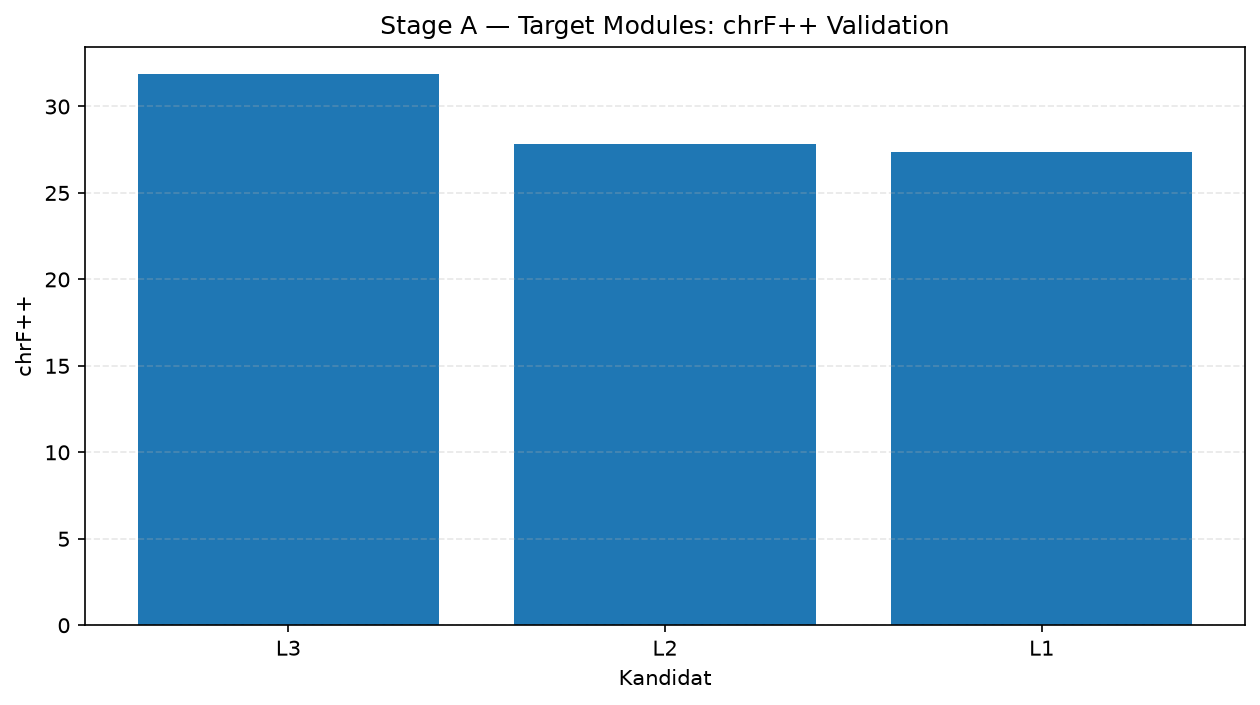

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/stage_a__target_modules.png


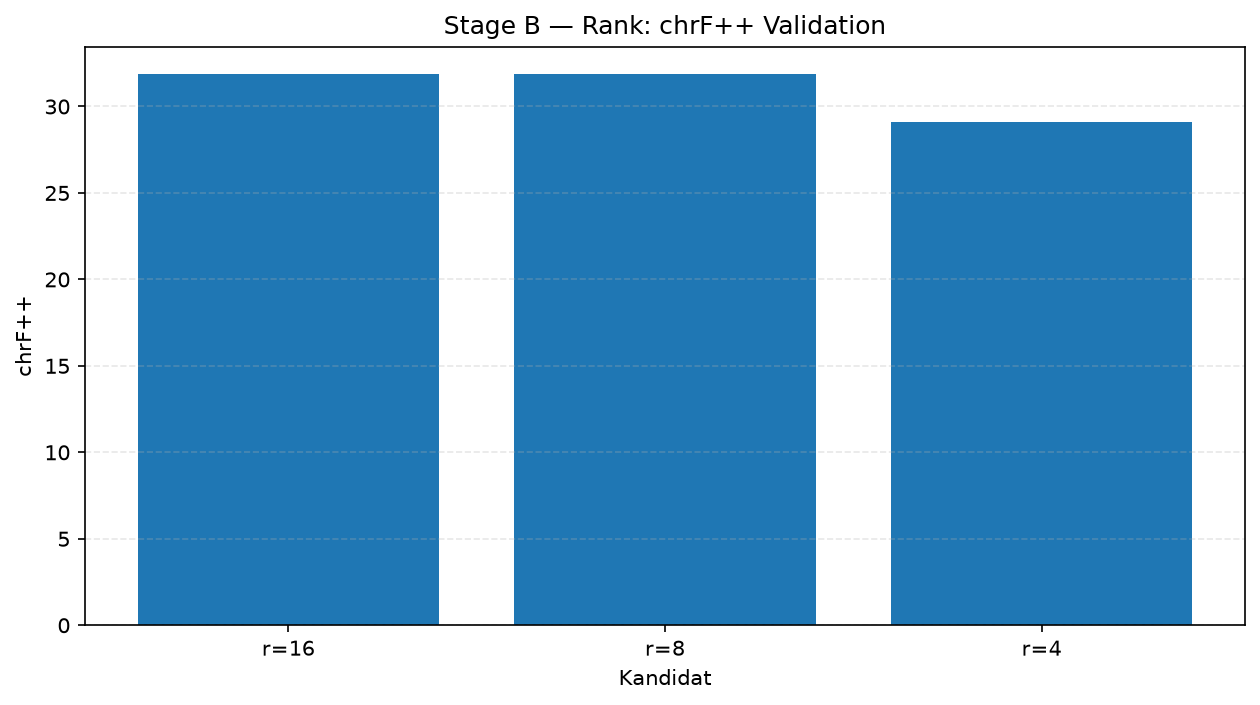

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/stage_b__rank.png


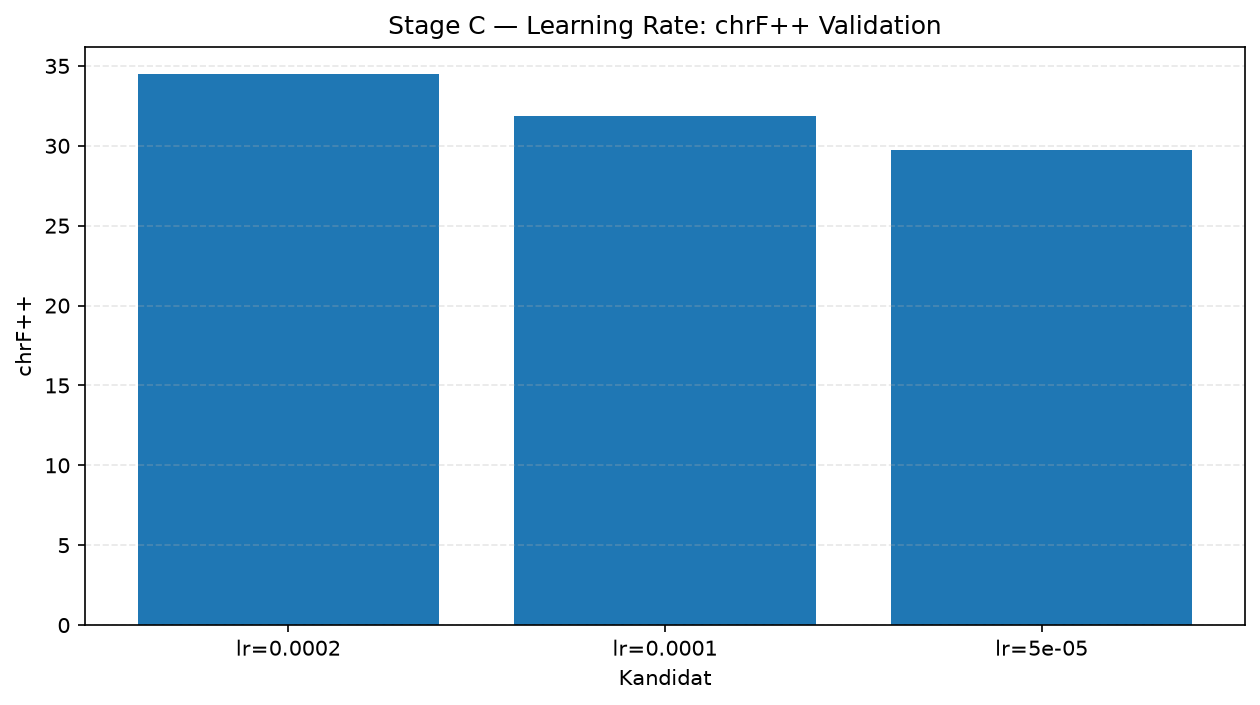

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/stage_c__learning_rate.png


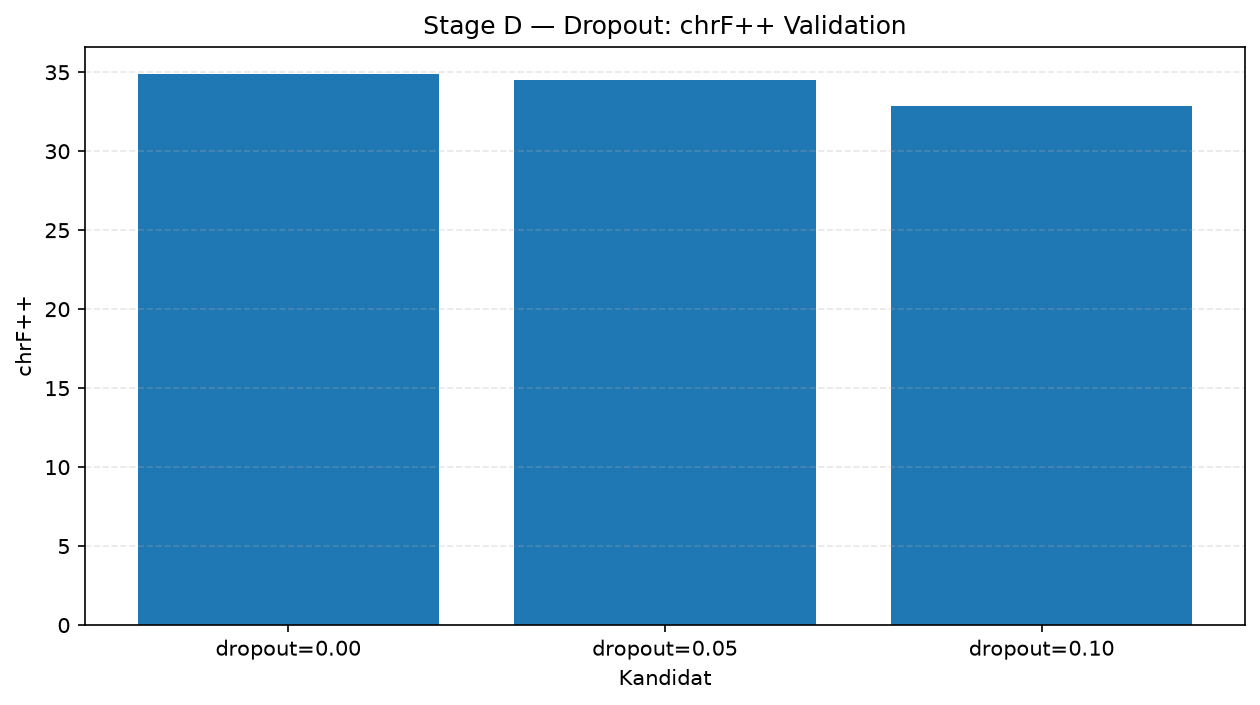

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/stage_d__dropout.png


,trial_id,checkpoint_name,checkpoint_path,step,epoch,eval_loss,validation_chrfpp,validation_bleu,predictions_path,evaluated_at_utc
2,trial_45d7c6df7a120bfe,checkpoint-159,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,159,3.000000,1.815980,34.885076,9.882648,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:23:08.029598+00:00
3,trial_45d7c6df7a120bfe,checkpoint-208,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,208,3.940048,2.155957,33.660055,8.887706,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:24:19.292595+00:00
1,trial_45d7c6df7a120bfe,checkpoint-106,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,106,2.000000,1.616873,30.478267,6.725790,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:21:58.254918+00:00
0,trial_45d7c6df7a120bfe,checkpoint-53,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,53,1.000000,1.628410,28.114060,6.072616,/workspace/10122233_CikitaMeydilvira_Skripsi/H...,2026-08-13T12:20:50.014684+00:00


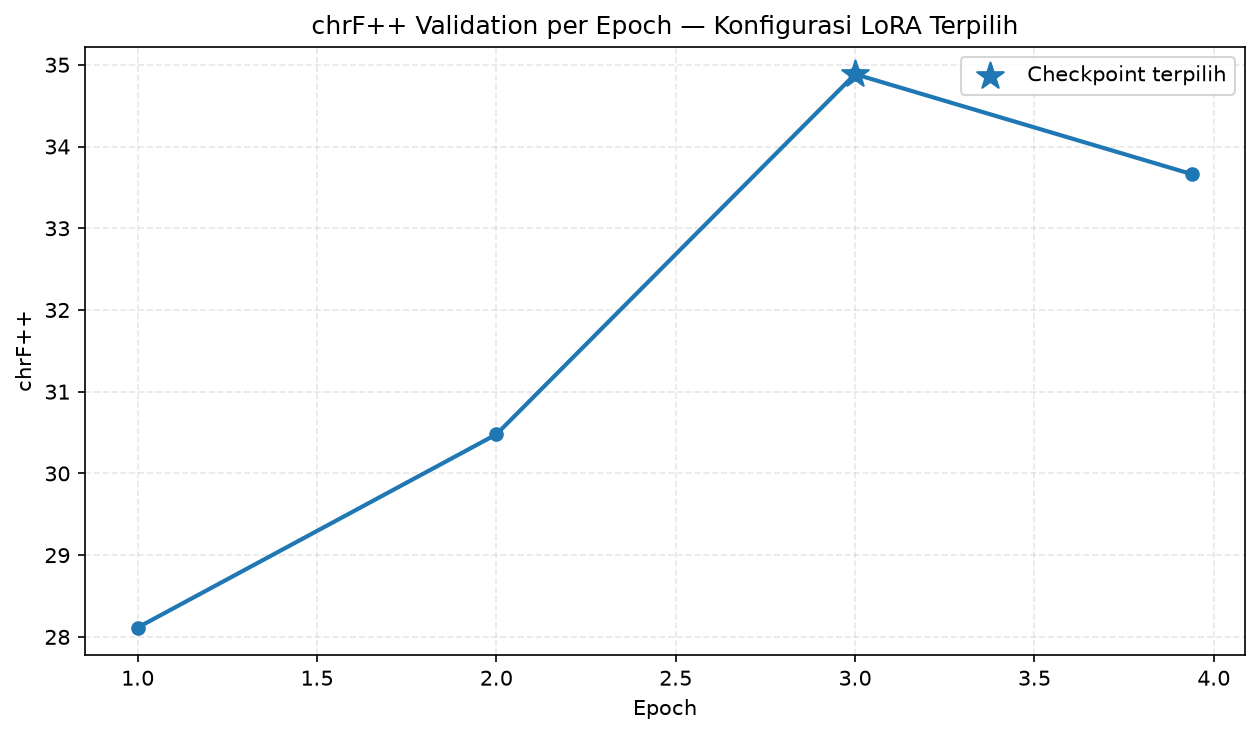

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/chrfpp_validation_per_epoch_lora_terpilih.png


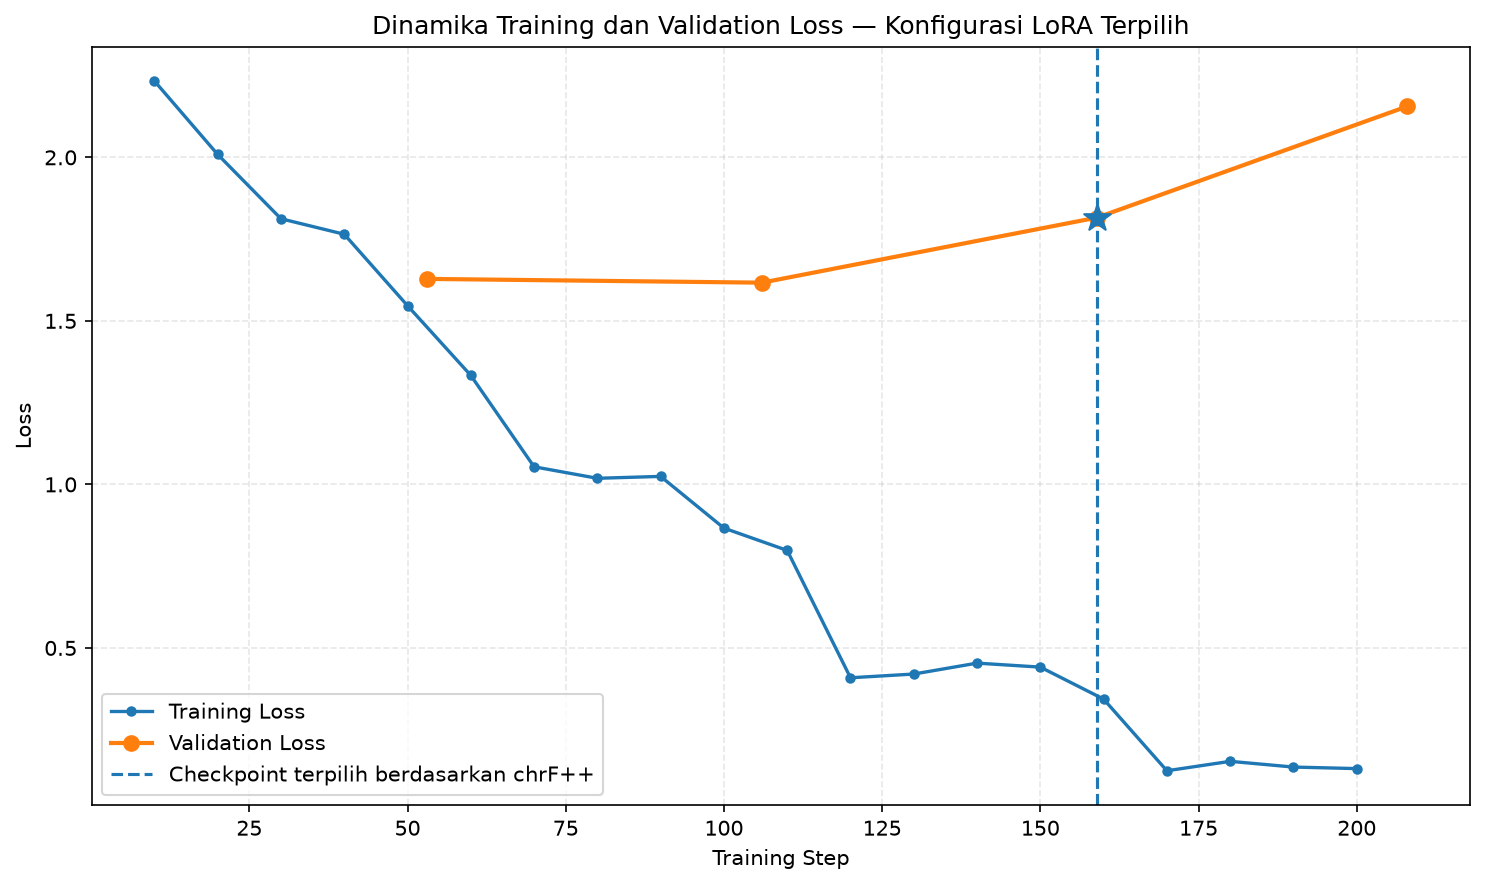

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/dinamika_loss_lora_terpilih.png


In [15]:
# ============================================================
# VISUALISASI STAGE + CHECKPOINT FINAL
# ============================================================

stage_tables = {
    "Stage A — Target Modules":
        stage_a_df,
    "Stage B — Rank":
        stage_b_df,
    "Stage C — Learning Rate":
        stage_c_df,
    "Stage D — Dropout":
        stage_d_df,
}

for title, dataframe in stage_tables.items():

    plot_df = (
        dataframe
        .sort_values(
            "validation_chrfpp",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

    fig, ax = plt.subplots(
        figsize=(
            8.5,
            4.8,
        ),
        dpi=150,
    )

    ax.bar(
        plot_df[
            "stage_candidate"
        ],
        plot_df[
            "validation_chrfpp"
        ],
    )

    ax.set_title(
        f"{title}: chrF++ Validation"
    )

    ax.set_xlabel(
        "Kandidat"
    )

    ax.set_ylabel(
        "chrF++"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3,
    )

    fig.tight_layout()

    filename = (
        title
        .lower()
        .replace(
            " ",
            "_",
        )
        .replace(
            "—",
            "",
        )
        .replace(
            "/",
            "_",
        )
    )

    path = (
        FIGURE_ROOT
        / f"{filename}.png"
    )

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        fig
    )

    print(
        "Tersimpan:",
        path,
    )


# ============================================================
# CHECKPOINT METRICS TRIAL FINAL
# ============================================================

final_checkpoint_metrics_path = (
    TRIAL_ROOT
    / FINAL_TRIAL_ID
    / "checkpoint_metrics.csv"
)

if not final_checkpoint_metrics_path.exists():

    raise FileNotFoundError(
        final_checkpoint_metrics_path
    )

final_checkpoint_df = pd.read_csv(
    final_checkpoint_metrics_path
)

display(
    final_checkpoint_df.sort_values(
        [
            "validation_chrfpp",
            "validation_bleu",
            "eval_loss",
        ],
        ascending=[
            False,
            False,
            True,
        ],
    )
)


# ============================================================
# GRAFIK chrF++ PER EPOCH
# ============================================================

fig1, ax1 = plt.subplots(
    figsize=(
        8.5,
        5,
    ),
    dpi=150,
)

ax1.plot(
    final_checkpoint_df[
        "epoch"
    ],
    final_checkpoint_df[
        "validation_chrfpp"
    ],
    marker="o",
    linewidth=2,
)

selected_epoch = (
    selected_config[
        "selected_checkpoint_epoch"
    ]
)

selected_chrf = (
    selected_config[
        "validation_chrfpp"
    ]
)

ax1.scatter(
    [
        selected_epoch
    ],
    [
        selected_chrf
    ],
    marker="*",
    s=180,
    zorder=5,
    label=(
        "Checkpoint terpilih"
    ),
)

ax1.set_title(
    "chrF++ Validation per Epoch — "
    "Konfigurasi LoRA Terpilih"
)

ax1.set_xlabel(
    "Epoch"
)

ax1.set_ylabel(
    "chrF++"
)

ax1.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

ax1.legend()

fig1.tight_layout()

chrf_path = (
    FIGURE_ROOT
    / "chrfpp_validation_per_epoch_lora_terpilih.png"
)

fig1.savefig(
    chrf_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(
    fig1
)

print(
    "Tersimpan:",
    chrf_path,
)


# ============================================================
# TRAINING LOSS + EVAL LOSS
# STAR = CHECKPOINT TERPILIH OLEH chrF++, BUKAN MIN LOSS
# ============================================================

final_log_path = (
    TRIAL_ROOT
    / FINAL_TRIAL_ID
    / "training_log.csv"
)

history = pd.read_csv(
    final_log_path
)

train_rows = (
    history[
        history[
            "loss"
        ].notna()
    ].copy()
    if "loss" in history.columns
    else pd.DataFrame()
)

eval_rows = (
    history[
        history[
            "eval_loss"
        ].notna()
    ].copy()
    if "eval_loss" in history.columns
    else pd.DataFrame()
)

fig2, ax2 = plt.subplots(
    figsize=(
        10,
        6,
    ),
    dpi=150,
)

if not train_rows.empty:

    ax2.plot(
        train_rows[
            "step"
        ],
        train_rows[
            "loss"
        ],
        marker="o",
        markersize=4,
        linewidth=1.6,
        label=(
            "Training Loss"
        ),
    )

if not eval_rows.empty:

    ax2.plot(
        eval_rows[
            "step"
        ],
        eval_rows[
            "eval_loss"
        ],
        marker="o",
        markersize=7,
        linewidth=2,
        label=(
            "Validation Loss"
        ),
    )

selected_step = int(
    selected_config[
        "selected_checkpoint_step"
    ]
)

selected_eval_loss = float(
    selected_config[
        "selected_checkpoint_eval_loss"
    ]
)

ax2.axvline(
    selected_step,
    linestyle="--",
    linewidth=1.5,
    label=(
        "Checkpoint terpilih "
        "berdasarkan chrF++"
    ),
)

ax2.scatter(
    [
        selected_step
    ],
    [
        selected_eval_loss
    ],
    marker="*",
    s=180,
    zorder=5,
)

ax2.set_title(
    "Dinamika Training dan Validation Loss — "
    "Konfigurasi LoRA Terpilih"
)

ax2.set_xlabel(
    "Training Step"
)

ax2.set_ylabel(
    "Loss"
)

ax2.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

ax2.legend()

fig2.tight_layout()

loss_path = (
    FIGURE_ROOT
    / "dinamika_loss_lora_terpilih.png"
)

fig2.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(
    fig2
)

print(
    "Tersimpan:",
    loss_path,
)


## 14. Narasi final yang harus diselaraskan ke BAB 3/BAB 4

Gunakan prinsip berikut:

> Penetapan konfigurasi Fine-Tuning LoRA dilakukan melalui pencarian bertahap pada data validasi. Tahap pertama membandingkan tiga cakupan target module, yaitu L1, L2, dan L3, dengan rank 16, alpha 32, learning rate 1×10⁻⁴, dan dropout 0,05 yang dibuat sama. Setelah cakupan target module terbaik ditetapkan, pencarian dilanjutkan secara berurutan terhadap rank, learning rate, dan dropout. Alpha mengikuti rank dengan rasio alpha/r sebesar 2. Maximum sequence length ditetapkan 640 token berdasarkan audit tokenizer dataset final, dengan panjang maksimum teramati 599 token sehingga tidak diperlukan truncation source/reference. Setiap kandidat dilatih selama empat epoch dan checkpoint disimpan pada setiap akhir epoch. Seluruh checkpoint kemudian dievaluasi secara deterministik pada 53 data validasi menggunakan chrF++ dan BLEU. Checkpoint dengan chrF++ tertinggi dipilih sebagai checkpoint representatif suatu kandidat, dengan BLEU dan validation loss sebagai kriteria pembeda berikutnya. Validation loss tetap digunakan untuk memantau dinamika konvergensi dan overfitting. Data uji tidak digunakan selama penetapan konfigurasi.

Interpretasi:
- **chrF++** = kriteria utama pemilihan checkpoint dan kandidat konfigurasi.
- **BLEU** = kriteria pendukung.
- **validation loss** = diagnostik training/generalization + tie-breaker.
- **Stage A** = perbandingan terkontrol pengaruh cakupan target module.
- **Stage B–D** = penyempurnaan konfigurasi setelah target module dikunci.
- `test.csv` = hanya untuk evaluasi final setelah konfigurasi terkunci.
- Jangan gunakan istilah **global optimum LoRA**.
- Gunakan istilah **konfigurasi terbaik di antara jalur pencarian bertahap yang diuji**.

Catatan penting:
Jika BAB 3/BAB 4 versi lama masih menyatakan bahwa hanya target module yang dicari, atau checkpoint dipilih berdasarkan validation loss terendah/early stopping, bagian tersebut perlu diselaraskan dengan protokol FINAL V6 ini sebelum skripsi difinalkan.


VISUALISASI DINAMIKA TRAINING LoRA
OUTPUT_ROOT    : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7
TRIAL_ROOT     : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/trials
STAGE_ROOT     : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/stages
FIGURE_ROOT    : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4

stage_A_target_modules → kandidat terpilih: L3

stage_B_rank → kandidat terpilih: r=16

stage_C_learning_rate → kandidat terpilih: lr=0.0002

stage_D_dropout → kandidat terpilih: dropout=0.00

Tabel seluruh loss per epoch tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/loss_diagnostics/all_stage_loss_per_epoch.csv

Stage A — Perbandingan Target Modules LoRA


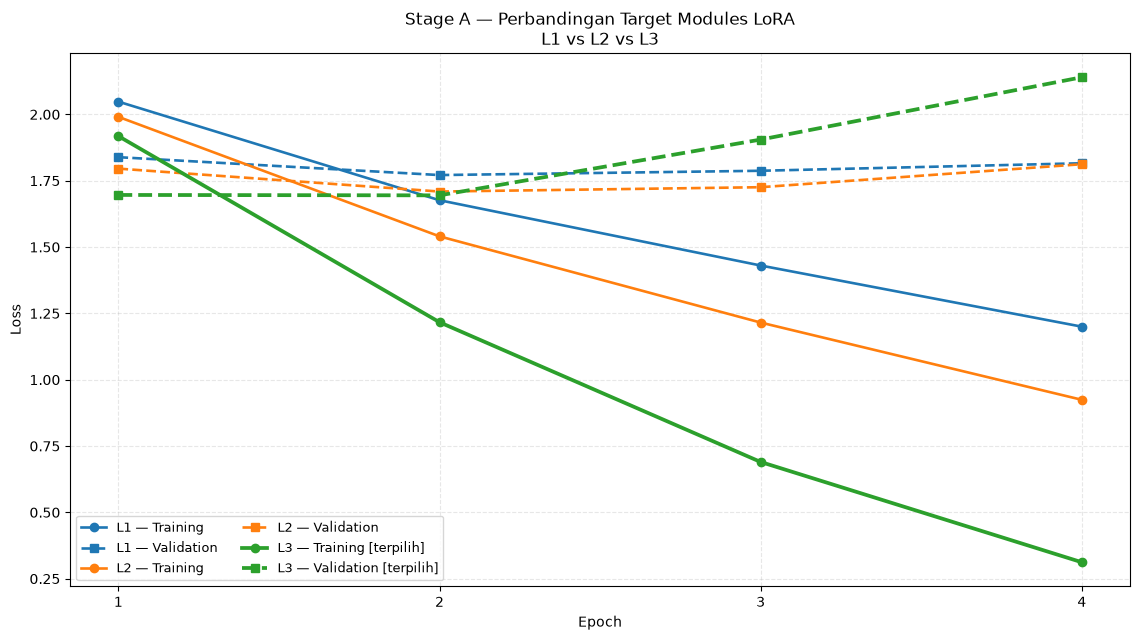

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/01_stage_A_perbandingan_loss_target_modules.png

Stage B — Perbandingan Rank LoRA


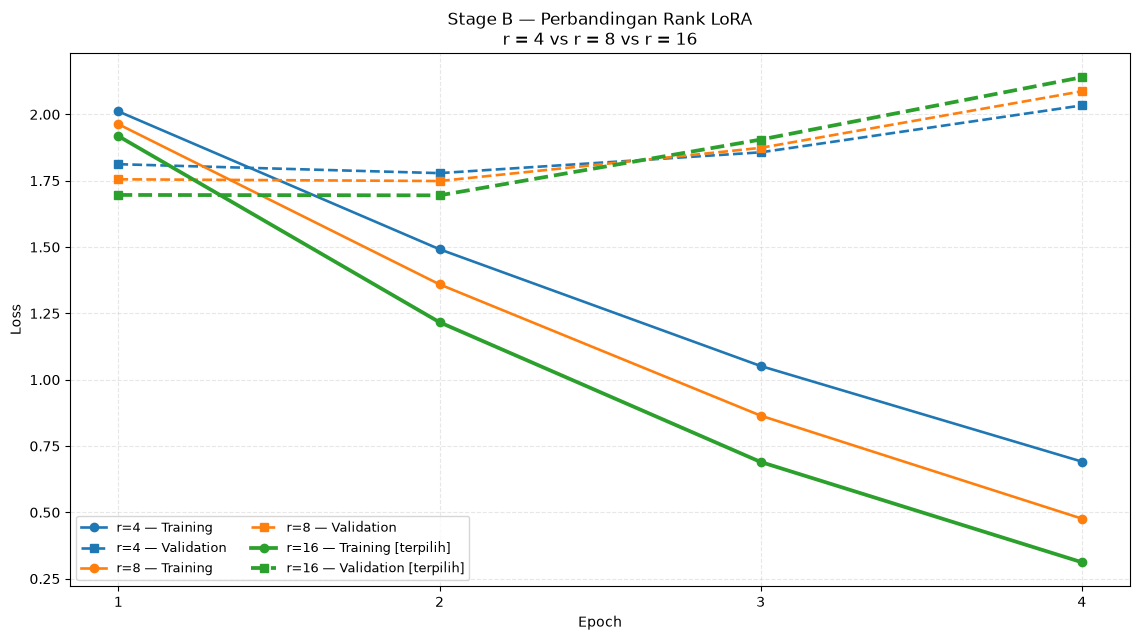

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/02_stage_B_perbandingan_loss_rank.png

Stage C — Perbandingan Learning Rate LoRA


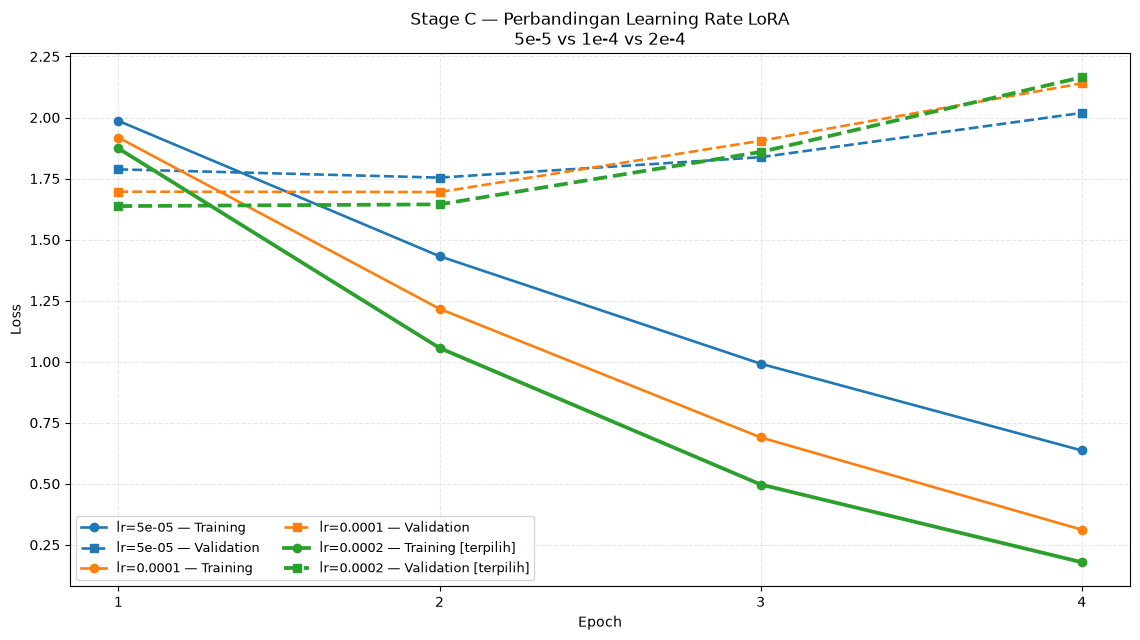

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/03_stage_C_perbandingan_loss_learning_rate.png

Stage D — Perbandingan LoRA Dropout


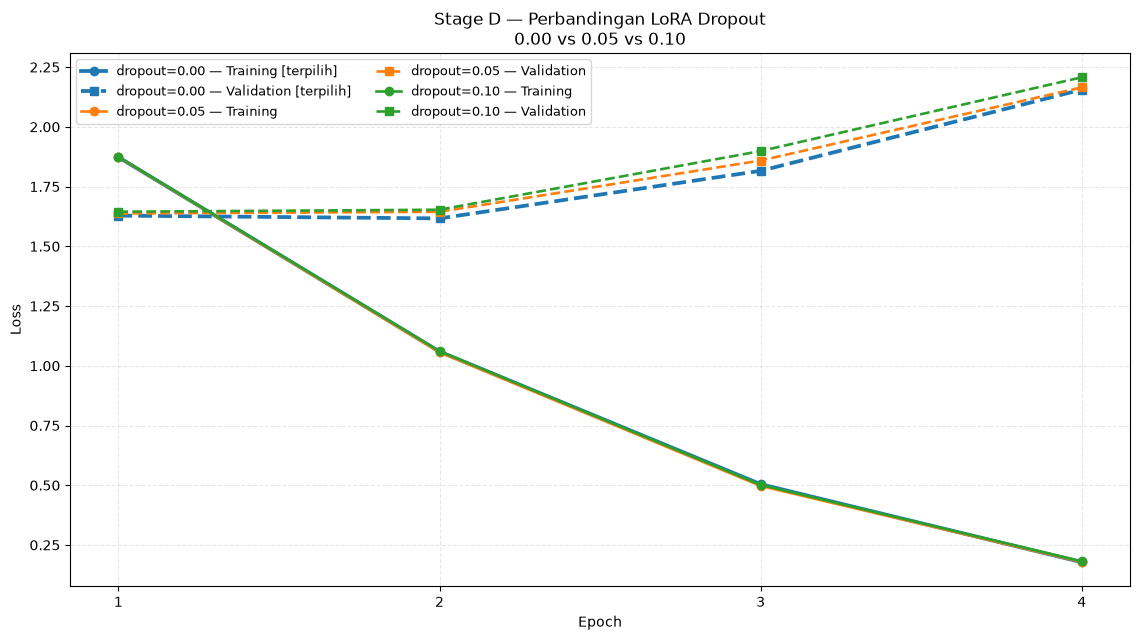

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/04_stage_D_perbandingan_loss_dropout.png


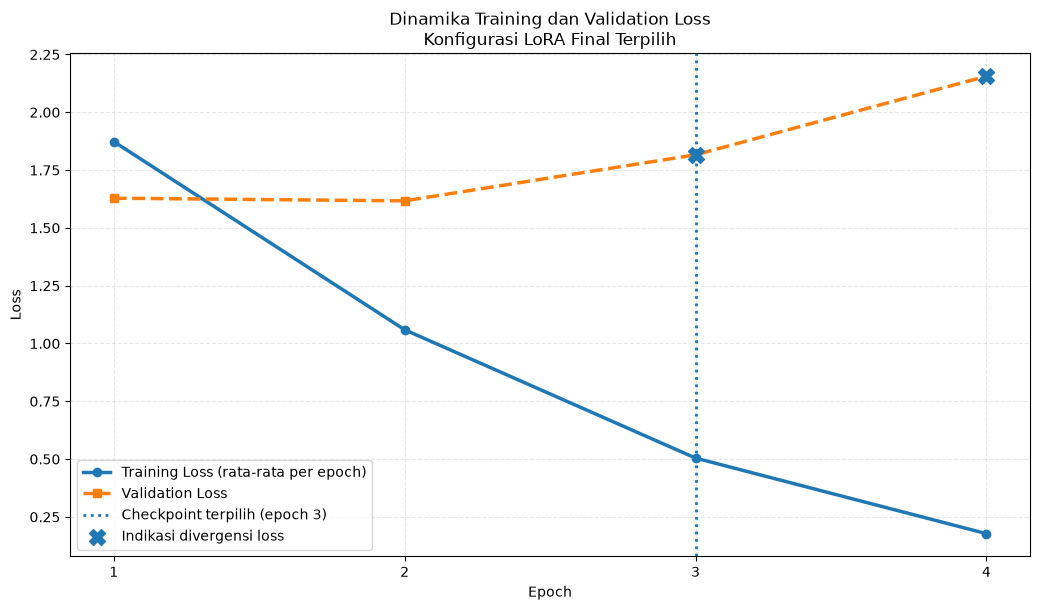

Tersimpan: /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/05_dinamika_loss_konfigurasi_lora_final.png

RINGKASAN DIAGNOSTIK SEMUA KONFIGURASI


,stage_name,stage_candidate,trial_id,selected_stage_candidate,minimum_validation_loss,minimum_validation_loss_epoch,maximum_validation_chrfpp,maximum_validation_chrfpp_epoch,loss_divergence_epochs,loss_and_quality_degradation_epochs
0,stage_A_target_modules,L1,trial_cdc9504fdd75729b,False,1.771283,2,27.380771,4,"3, 4",-
1,stage_A_target_modules,L2,trial_0e35dfb2e0e1f039,False,1.709163,2,27.842899,3,"3, 4",4
2,stage_A_target_modules,L3,trial_4d9728224050c519,True,1.694838,2,31.875988,3,"3, 4",4
3,stage_B_rank,r=4,trial_22811aacbd526f6b,False,1.778572,2,29.089444,4,"3, 4",-
4,stage_B_rank,r=8,trial_66aad75f2740b81c,False,1.748837,2,31.852642,4,"3, 4",-
5,stage_B_rank,r=16,trial_4d9728224050c519,True,1.694838,2,31.875988,3,"3, 4",4
6,stage_C_learning_rate,lr=5e-05,trial_24b949f8c63944d2,False,1.754039,2,29.757055,3,"3, 4",4
7,stage_C_learning_rate,lr=0.0001,trial_4d9728224050c519,False,1.694838,2,31.875988,3,"3, 4",4
8,stage_C_learning_rate,lr=0.0002,trial_957abfc6fc939f6e,True,1.637365,1,34.490831,3,"2, 3, 4",4
9,stage_D_dropout,dropout=0.00,trial_45d7c6df7a120bfe,True,1.616873,2,34.885076,3,"3, 4",4



KONFIGURASI LoRA FINAL — DETAIL PER EPOCH


,epoch,checkpoint_name,training_loss_mean,training_loss_last,validation_loss,validation_chrfpp,validation_bleu,delta_training_loss,delta_validation_loss,delta_chrfpp,loss_divergence_signal,loss_and_quality_degradation_signal
0,1,checkpoint-53,1.8732,1.5465,1.6284,28.1141,6.0726,NaN,NaN,NaN,False,False
1,2,checkpoint-106,1.0594,0.8664,1.6169,30.4783,6.7258,-0.8139,-0.0115,2.3642,False,False
2,3,checkpoint-159,0.5044,0.4414,1.8160,34.8851,9.8826,-0.5549,0.1991,4.4068,True,False
3,4,checkpoint-208,0.1777,0.1311,2.1560,33.6601,8.8877,-0.3268,0.3400,-1.2250,True,True



SELESAI — OUTPUT VISUALISASI BAB 4

GRAFIK:
1. Stage A Target Modules : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/01_stage_A_perbandingan_loss_target_modules.png
2. Stage B Rank           : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/02_stage_B_perbandingan_loss_rank.png
3. Stage C Learning Rate  : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/03_stage_C_perbandingan_loss_learning_rate.png
4. Stage D Dropout        : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/04_stage_D_perbandingan_loss_dropout.png
5. LoRA Final             : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/config_selection/lora_target_first_v7/figures_bab4/05_dinamika_loss_konfigurasi_lora_final.png

TABEL:
Loss seluruh stage       : /workspace/10122233_CikitaMeydilvira_Skripsi/Hasil/c

In [16]:
# ============================================================
# VISUALISASI DINAMIKA TRAINING LoRA — FINAL UNTUK BAB 4
# ============================================================
# TEMPEL SEBAGAI CELL PALING TERAKHIR NOTEBOOK LoRA V7
#
# Menghasilkan 5 grafik:
# 1. Stage A — L1 vs L2 vs L3
# 2. Stage B — r=4 vs r=8 vs r=16
# 3. Stage C — LR 5e-5 vs 1e-4 vs 2e-4
# 4. Stage D — dropout 0.00 vs 0.05 vs 0.10
# 5. Konfigurasi LoRA final terpilih
#
# Setiap kandidat menampilkan:
# - Training loss rata-rata per epoch = garis solid
# - Validation loss per epoch        = garis putus-putus
#
# Selain grafik, cell menyimpan:
# - tabel loss per epoch semua kandidat
# - tabel indikasi divergensi loss
#
# TIDAK ADA TRAINING ULANG.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ============================================================
# 1. PATH
# ============================================================

# Jika dijalankan langsung setelah notebook V7,
# variabel ini sebenarnya sudah tersedia.
# Fallback disediakan agar lebih aman.

if "PROJECT_ROOT" not in globals():
    PROJECT_ROOT = Path(
        "/workspace/10122233_CikitaMeydilvira_Skripsi"
    )

if "OUTPUT_ROOT" not in globals():
    OUTPUT_ROOT = (
        PROJECT_ROOT
        / "Hasil"
        / "config_selection"
        / "lora_target_first_v7"
    )

if "TRIAL_ROOT" not in globals():
    TRIAL_ROOT = (
        OUTPUT_ROOT
        / "trials"
    )

if "STAGE_ROOT" not in globals():
    STAGE_ROOT = (
        OUTPUT_ROOT
        / "stages"
    )

if "FIGURE_ROOT" not in globals():
    FIGURE_ROOT = (
        OUTPUT_ROOT
        / "figures_bab4"
    )


DIAGNOSTIC_ROOT = (
    OUTPUT_ROOT
    / "loss_diagnostics"
)

FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

DIAGNOSTIC_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


print("=" * 80)
print("VISUALISASI DINAMIKA TRAINING LoRA")
print("=" * 80)

print(
    "OUTPUT_ROOT    :",
    OUTPUT_ROOT,
)

print(
    "TRIAL_ROOT     :",
    TRIAL_ROOT,
)

print(
    "STAGE_ROOT     :",
    STAGE_ROOT,
)

print(
    "FIGURE_ROOT    :",
    FIGURE_ROOT,
)


# ============================================================
# 2. DEFINISI STAGE
# ============================================================

STAGES = {

    "stage_A_target_modules": {
        "title":
            "Stage A — Perbandingan Target Modules LoRA",

        "description":
            "L1 vs L2 vs L3",

        "filename":
            "01_stage_A_perbandingan_loss_target_modules.png",
    },

    "stage_B_rank": {
        "title":
            "Stage B — Perbandingan Rank LoRA",

        "description":
            "r = 4 vs r = 8 vs r = 16",

        "filename":
            "02_stage_B_perbandingan_loss_rank.png",
    },

    "stage_C_learning_rate": {
        "title":
            "Stage C — Perbandingan Learning Rate LoRA",

        "description":
            "5e-5 vs 1e-4 vs 2e-4",

        "filename":
            "03_stage_C_perbandingan_loss_learning_rate.png",
    },

    "stage_D_dropout": {
        "title":
            "Stage D — Perbandingan LoRA Dropout",

        "description":
            "0.00 vs 0.05 vs 0.10",

        "filename":
            "04_stage_D_perbandingan_loss_dropout.png",
    },
}


# ============================================================
# 3. HELPER PEMILIHAN KANDIDAT STAGE
# ============================================================
# Sama dengan aturan notebook V7:
#
# 1. chrF++ lebih tinggi
# 2. BLEU lebih tinggi
# 3. validation loss lebih rendah
# 4. trainable parameter lebih sedikit
# ============================================================

def select_stage_winner(
    stage_df: pd.DataFrame,
) -> pd.Series:

    df = stage_df.copy()

    numeric_columns = [
        "validation_chrfpp",
        "validation_bleu",
        "selected_checkpoint_eval_loss",
        "trainable_parameters",
    ]

    for column in numeric_columns:

        if column not in df.columns:
            raise RuntimeError(
                f"Kolom {column} tidak ditemukan "
                "pada stage CSV."
            )

        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

    ranked = (
        df
        .sort_values(
            [
                "validation_chrfpp",
                "validation_bleu",
                "selected_checkpoint_eval_loss",
                "trainable_parameters",
            ],
            ascending=[
                False,
                False,
                True,
                True,
            ],
            kind="stable",
        )
        .reset_index(
            drop=True
        )
    )

    return ranked.iloc[0]


# ============================================================
# 4. HELPER MEMBENTUK LOSS PER EPOCH
# ============================================================
#
# Validation loss:
# → diambil langsung dari checkpoint_metrics.csv
#
# Training loss:
# → rata-rata log training yang berada
#   di antara checkpoint epoch sebelumnya
#   sampai checkpoint epoch saat ini.
#
# Dengan cara ini:
# epoch 1 = step awal sampai checkpoint epoch 1
# epoch 2 = setelah checkpoint 1 sampai checkpoint 2
# dst.
# ============================================================

def load_trial_epoch_metrics(
    trial_id: str,
) -> pd.DataFrame:

    trial_dir = (
        TRIAL_ROOT
        / str(
            trial_id
        )
    )

    training_log_path = (
        trial_dir
        / "training_log.csv"
    )

    checkpoint_metrics_path = (
        trial_dir
        / "checkpoint_metrics.csv"
    )


    if not training_log_path.exists():

        raise FileNotFoundError(
            "training_log.csv tidak ditemukan:\n"
            f"{training_log_path}"
        )


    if not checkpoint_metrics_path.exists():

        raise FileNotFoundError(
            "checkpoint_metrics.csv tidak ditemukan:\n"
            f"{checkpoint_metrics_path}"
        )


    # --------------------------------------------------------
    # TRAINING LOG
    # --------------------------------------------------------

    training_log = pd.read_csv(
        training_log_path,
        encoding="utf-8-sig",
    )


    required_training_columns = [
        "step",
        "loss",
    ]

    missing_training = [
        column
        for column in required_training_columns
        if column not in training_log.columns
    ]

    if missing_training:

        raise RuntimeError(
            f"{trial_id}: training_log.csv kehilangan "
            f"kolom {missing_training}"
        )


    training_log["step"] = pd.to_numeric(
        training_log["step"],
        errors="coerce",
    )

    training_log["loss"] = pd.to_numeric(
        training_log["loss"],
        errors="coerce",
    )


    train_rows = (
        training_log[
            training_log[
                "step"
            ].notna()
            &
            training_log[
                "loss"
            ].notna()
        ]
        .copy()
        .sort_values(
            "step",
            kind="stable",
        )
    )


    # --------------------------------------------------------
    # CHECKPOINT METRICS
    # --------------------------------------------------------

    checkpoint_metrics = pd.read_csv(
        checkpoint_metrics_path,
        encoding="utf-8-sig",
    )


    required_checkpoint_columns = [
        "checkpoint_name",
        "step",
        "eval_loss",
        "validation_chrfpp",
        "validation_bleu",
    ]

    missing_checkpoint = [
        column
        for column in required_checkpoint_columns
        if column not in checkpoint_metrics.columns
    ]

    if missing_checkpoint:

        raise RuntimeError(
            f"{trial_id}: checkpoint_metrics.csv kehilangan "
            f"kolom {missing_checkpoint}"
        )


    for column in [
        "step",
        "eval_loss",
        "validation_chrfpp",
        "validation_bleu",
    ]:

        checkpoint_metrics[column] = pd.to_numeric(
            checkpoint_metrics[column],
            errors="coerce",
        )


    checkpoint_metrics = (
        checkpoint_metrics
        .dropna(
            subset=[
                "step",
                "eval_loss",
            ]
        )
        .sort_values(
            "step",
            kind="stable",
        )
        .reset_index(
            drop=True
        )
    )


    if checkpoint_metrics.empty:

        raise RuntimeError(
            f"{trial_id}: tidak ada checkpoint valid."
        )


    # Epoch penelitian = checkpoint akhir epoch
    checkpoint_metrics[
        "epoch_index"
    ] = np.arange(
        1,
        len(
            checkpoint_metrics
        ) + 1,
    )


    # --------------------------------------------------------
    # AGREGASI TRAINING LOSS PER EPOCH
    # --------------------------------------------------------

    rows = []

    previous_step = 0


    for checkpoint in checkpoint_metrics.itertuples(
        index=False
    ):

        current_step = int(
            checkpoint.step
        )


        epoch_train_rows = (
            train_rows[
                (
                    train_rows[
                        "step"
                    ]
                    >
                    previous_step
                )
                &
                (
                    train_rows[
                        "step"
                    ]
                    <=
                    current_step
                )
            ]
            .copy()
        )


        if epoch_train_rows.empty:

            train_loss_mean = np.nan
            train_loss_last = np.nan

        else:

            train_loss_mean = float(
                epoch_train_rows[
                    "loss"
                ].mean()
            )

            train_loss_last = float(
                epoch_train_rows.iloc[
                    -1
                ][
                    "loss"
                ]
            )


        rows.append(
            {
                "trial_id":
                    str(
                        trial_id
                    ),

                "epoch":
                    int(
                        checkpoint.epoch_index
                    ),

                "checkpoint_name":
                    str(
                        checkpoint.checkpoint_name
                    ),

                "checkpoint_step":
                    current_step,

                "training_loss_mean":
                    train_loss_mean,

                "training_loss_last":
                    train_loss_last,

                "validation_loss":
                    float(
                        checkpoint.eval_loss
                    ),

                "validation_chrfpp":
                    float(
                        checkpoint.validation_chrfpp
                    ),

                "validation_bleu":
                    float(
                        checkpoint.validation_bleu
                    ),
            }
        )


        previous_step = (
            current_step
        )


    result = pd.DataFrame(
        rows
    )


    # --------------------------------------------------------
    # PERUBAHAN ANTAR-EPOCH
    # --------------------------------------------------------

    result[
        "delta_training_loss"
    ] = (
        result[
            "training_loss_mean"
        ]
        .diff()
    )


    result[
        "delta_validation_loss"
    ] = (
        result[
            "validation_loss"
        ]
        .diff()
    )


    result[
        "delta_chrfpp"
    ] = (
        result[
            "validation_chrfpp"
        ]
        .diff()
    )


    # --------------------------------------------------------
    # INDIKASI DIVERGENSI
    #
    # training loss turun
    # tetapi validation loss naik
    #
    # Ini hanya indikasi awal, bukan label mutlak overfitting.
    # --------------------------------------------------------

    result[
        "loss_divergence_signal"
    ] = (
        (
            result[
                "delta_training_loss"
            ]
            <
            0
        )
        &
        (
            result[
                "delta_validation_loss"
            ]
            >
            0
        )
    )


    # Sinyal lebih kuat:
    # training loss turun
    # validation loss naik
    # chrF++ ikut turun

    result[
        "loss_and_quality_degradation_signal"
    ] = (
        result[
            "loss_divergence_signal"
        ]
        &
        (
            result[
                "delta_chrfpp"
            ]
            <
            0
        )
    )


    return result


# ============================================================
# 5. LOAD SEMUA STAGE
# ============================================================

all_epoch_rows = []

stage_data = {}


for stage_name, stage_info in STAGES.items():

    stage_csv_path = (
        STAGE_ROOT
        / f"{stage_name}.csv"
    )


    if not stage_csv_path.exists():

        raise FileNotFoundError(
            "Stage CSV belum tersedia:\n"
            f"{stage_csv_path}\n\n"
            "Pastikan Stage A–D sudah selesai sebelum "
            "menjalankan visualisasi."
        )


    stage_df = pd.read_csv(
        stage_csv_path,
        encoding="utf-8-sig",
    )


    required_stage_columns = [
        "stage_candidate",
        "trial_id",
        "validation_chrfpp",
        "validation_bleu",
        "selected_checkpoint_eval_loss",
        "trainable_parameters",
    ]


    missing = [
        column
        for column in required_stage_columns
        if column not in stage_df.columns
    ]


    if missing:

        raise RuntimeError(
            f"{stage_name}: stage CSV kehilangan "
            f"kolom {missing}"
        )


    stage_winner = (
        select_stage_winner(
            stage_df
        )
    )


    winner_candidate = str(
        stage_winner[
            "stage_candidate"
        ]
    )


    stage_curves = {}


    for row in stage_df.itertuples(
        index=False
    ):

        candidate = str(
            row.stage_candidate
        )

        trial_id = str(
            row.trial_id
        )


        curve = (
            load_trial_epoch_metrics(
                trial_id
            )
        )


        curve.insert(
            0,
            "stage_name",
            stage_name,
        )

        curve.insert(
            1,
            "stage_candidate",
            candidate,
        )


        curve[
            "selected_stage_candidate"
        ] = (
            candidate
            ==
            winner_candidate
        )


        stage_curves[
            candidate
        ] = curve


        all_epoch_rows.append(
            curve
        )


    stage_data[
        stage_name
    ] = {
        "stage_df":
            stage_df,

        "winner":
            stage_winner,

        "winner_candidate":
            winner_candidate,

        "curves":
            stage_curves,
    }


    print()
    print(
        stage_name,
        "→ kandidat terpilih:",
        winner_candidate,
    )


# ============================================================
# 6. SATUKAN DATA LOSS SEMUA STAGE
# ============================================================

all_epoch_df = pd.concat(
    all_epoch_rows,
    ignore_index=True,
)


ALL_EPOCH_PATH = (
    DIAGNOSTIC_ROOT
    / "all_stage_loss_per_epoch.csv"
)


all_epoch_df.to_csv(
    ALL_EPOCH_PATH,
    index=False,
    encoding="utf-8-sig",
)


print()
print(
    "Tabel seluruh loss per epoch tersimpan:",
    ALL_EPOCH_PATH,
)


# ============================================================
# 7. FUNGSI PLOT PER STAGE
# ============================================================

def plot_stage_comparison(
    stage_name: str,
    stage_info: dict,
):

    data = (
        stage_data[
            stage_name
        ]
    )


    curves = (
        data[
            "curves"
        ]
    )


    winner_candidate = (
        data[
            "winner_candidate"
        ]
    )


    fig, ax = plt.subplots(
        figsize=(
            11.5,
            6.5,
        )
    )


    max_epoch = 0


    for candidate, curve in curves.items():

        max_epoch = max(
            max_epoch,
            int(
                curve[
                    "epoch"
                ].max()
            ),
        )


        # ----------------------------------------------------
        # Gunakan warna yang sama untuk train dan validation
        # kandidat yang sama.
        #
        # Solid  = training loss
        # Dashed = validation loss
        # ----------------------------------------------------

        train_line, = ax.plot(
            curve[
                "epoch"
            ],
            curve[
                "training_loss_mean"
            ],
            marker="o",
            linewidth=(
                2.7
                if candidate == winner_candidate
                else 1.9
            ),
            label=(
                f"{candidate} — Training"
                +
                (
                    " [terpilih]"
                    if candidate
                    ==
                    winner_candidate
                    else ""
                )
            ),
        )


        ax.plot(
            curve[
                "epoch"
            ],
            curve[
                "validation_loss"
            ],
            marker="s",
            linestyle="--",
            linewidth=(
                2.7
                if candidate == winner_candidate
                else 1.9
            ),
            color=(
                train_line.get_color()
            ),
            label=(
                f"{candidate} — Validation"
                +
                (
                    " [terpilih]"
                    if candidate
                    ==
                    winner_candidate
                    else ""
                )
            ),
        )


    ax.set_title(
        stage_info[
            "title"
        ]
        + "\n"
        + stage_info[
            "description"
        ]
    )


    ax.set_xlabel(
        "Epoch"
    )


    ax.set_ylabel(
        "Loss"
    )


    ax.set_xticks(
        range(
            1,
            max_epoch + 1,
        )
    )


    ax.grid(
        True,
        linestyle="--",
        alpha=0.30,
    )


    ax.legend(
        ncol=2,
        fontsize=9,
    )


    fig.tight_layout()


    output_path = (
        FIGURE_ROOT
        / stage_info[
            "filename"
        ]
    )


    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )


    plt.show()

    plt.close(
        fig
    )


    print(
        "Tersimpan:",
        output_path,
    )


    return output_path


# ============================================================
# 8. GRAFIK 1–4 — PERBANDINGAN SETIAP STAGE
# ============================================================

stage_figure_paths = {}


for stage_name, stage_info in STAGES.items():

    print()
    print("=" * 80)
    print(
        stage_info[
            "title"
        ]
    )
    print("=" * 80)


    stage_figure_paths[
        stage_name
    ] = (
        plot_stage_comparison(
            stage_name,
            stage_info,
        )
    )


# ============================================================
# 9. KONFIGURASI FINAL
# ============================================================
#
# Final trial = pemenang Stage D
# karena Stage D merupakan tahap terakhir pencarian.
# ============================================================

stage_d_winner = (
    stage_data[
        "stage_D_dropout"
    ][
        "winner"
    ]
)


FINAL_TRIAL_ID_VIS = str(
    stage_d_winner[
        "trial_id"
    ]
)


FINAL_CANDIDATE_VIS = str(
    stage_d_winner[
        "stage_candidate"
    ]
)


FINAL_SELECTED_CHECKPOINT = str(
    stage_d_winner[
        "selected_checkpoint_name"
    ]
)


final_curve = (
    load_trial_epoch_metrics(
        FINAL_TRIAL_ID_VIS
    )
)


selected_checkpoint_rows = (
    final_curve[
        final_curve[
            "checkpoint_name"
        ]
        ==
        FINAL_SELECTED_CHECKPOINT
    ]
)


if not selected_checkpoint_rows.empty:

    selected_epoch = int(
        selected_checkpoint_rows.iloc[
            0
        ][
            "epoch"
        ]
    )

else:

    # fallback bila nama checkpoint tidak ditemukan
    selected_epoch = int(
        final_curve.loc[
            final_curve[
                "validation_chrfpp"
            ].idxmax(),
            "epoch",
        ]
    )


# ============================================================
# 10. GRAFIK 5 — KONFIGURASI FINAL
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        10.5,
        6.2,
    )
)


train_line, = ax.plot(
    final_curve[
        "epoch"
    ],
    final_curve[
        "training_loss_mean"
    ],
    marker="o",
    linewidth=2.5,
    label=(
        "Training Loss "
        "(rata-rata per epoch)"
    ),
)


ax.plot(
    final_curve[
        "epoch"
    ],
    final_curve[
        "validation_loss"
    ],
    marker="s",
    linestyle="--",
    linewidth=2.5,
    label="Validation Loss",
)


ax.axvline(
    selected_epoch,
    linestyle=":",
    linewidth=2,
    label=(
        f"Checkpoint terpilih "
        f"(epoch {selected_epoch})"
    ),
)


# Tandai epoch dengan indikasi divergensi loss
signal_rows = (
    final_curve[
        final_curve[
            "loss_divergence_signal"
        ]
    ]
)


if not signal_rows.empty:

    ax.scatter(
        signal_rows[
            "epoch"
        ],
        signal_rows[
            "validation_loss"
        ],
        marker="X",
        s=130,
        zorder=5,
        label=(
            "Indikasi divergensi loss"
        ),
    )


ax.set_title(
    "Dinamika Training dan Validation Loss\n"
    "Konfigurasi LoRA Final Terpilih"
)


ax.set_xlabel(
    "Epoch"
)


ax.set_ylabel(
    "Loss"
)


ax.set_xticks(
    final_curve[
        "epoch"
    ].tolist()
)


ax.grid(
    True,
    linestyle="--",
    alpha=0.30,
)


ax.legend()


fig.tight_layout()


FINAL_FIGURE_PATH = (
    FIGURE_ROOT
    / "05_dinamika_loss_konfigurasi_lora_final.png"
)


fig.savefig(
    FINAL_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)


plt.show()

plt.close(
    fig
)


print(
    "Tersimpan:",
    FINAL_FIGURE_PATH,
)


# ============================================================
# 11. TABEL RINGKAS INDIKASI DIVERGENSI
# ============================================================
#
# Penting:
# Ini BUKAN label otomatis "overfit".
#
# loss_divergence_signal:
# training loss turun
# tetapi validation loss naik
#
# loss_and_quality_degradation_signal:
# kondisi di atas + chrF++ ikut turun
# ============================================================

diagnostic_summary_rows = []


for stage_name, info in stage_data.items():

    for candidate, curve in info[
        "curves"
    ].items():

        divergence_epochs = (
            curve.loc[
                curve[
                    "loss_divergence_signal"
                ],
                "epoch",
            ]
            .astype(int)
            .tolist()
        )


        strong_signal_epochs = (
            curve.loc[
                curve[
                    "loss_and_quality_degradation_signal"
                ],
                "epoch",
            ]
            .astype(int)
            .tolist()
        )


        min_val_idx = (
            curve[
                "validation_loss"
            ].idxmin()
        )


        max_chrf_idx = (
            curve[
                "validation_chrfpp"
            ].idxmax()
        )


        diagnostic_summary_rows.append(
            {
                "stage_name":
                    stage_name,

                "stage_candidate":
                    candidate,

                "trial_id":
                    str(
                        curve.iloc[
                            0
                        ][
                            "trial_id"
                        ]
                    ),

                "selected_stage_candidate":
                    bool(
                        candidate
                        ==
                        info[
                            "winner_candidate"
                        ]
                    ),

                "minimum_validation_loss":
                    float(
                        curve.loc[
                            min_val_idx,
                            "validation_loss",
                        ]
                    ),

                "minimum_validation_loss_epoch":
                    int(
                        curve.loc[
                            min_val_idx,
                            "epoch",
                        ]
                    ),

                "maximum_validation_chrfpp":
                    float(
                        curve.loc[
                            max_chrf_idx,
                            "validation_chrfpp",
                        ]
                    ),

                "maximum_validation_chrfpp_epoch":
                    int(
                        curve.loc[
                            max_chrf_idx,
                            "epoch",
                        ]
                    ),

                "loss_divergence_epochs":
                    (
                        ", ".join(
                            map(
                                str,
                                divergence_epochs,
                            )
                        )
                        if divergence_epochs
                        else "-"
                    ),

                "loss_and_quality_degradation_epochs":
                    (
                        ", ".join(
                            map(
                                str,
                                strong_signal_epochs,
                            )
                        )
                        if strong_signal_epochs
                        else "-"
                    ),
            }
        )


diagnostic_summary_df = pd.DataFrame(
    diagnostic_summary_rows
)


DIAGNOSTIC_SUMMARY_PATH = (
    DIAGNOSTIC_ROOT
    / "loss_divergence_summary_all_stages.csv"
)


diagnostic_summary_df.to_csv(
    DIAGNOSTIC_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)


print()
print("=" * 80)
print("RINGKASAN DIAGNOSTIK SEMUA KONFIGURASI")
print("=" * 80)


display(
    diagnostic_summary_df
)


# ============================================================
# 12. TABEL FINAL PER EPOCH
# ============================================================

print()
print("=" * 80)
print("KONFIGURASI LoRA FINAL — DETAIL PER EPOCH")
print("=" * 80)


final_display = (
    final_curve[
        [
            "epoch",
            "checkpoint_name",
            "training_loss_mean",
            "training_loss_last",
            "validation_loss",
            "validation_chrfpp",
            "validation_bleu",
            "delta_training_loss",
            "delta_validation_loss",
            "delta_chrfpp",
            "loss_divergence_signal",
            "loss_and_quality_degradation_signal",
        ]
    ]
    .copy()
)


display(
    final_display.round(
        4
    )
)


FINAL_EPOCH_PATH = (
    DIAGNOSTIC_ROOT
    / "final_lora_loss_per_epoch.csv"
)


final_display.to_csv(
    FINAL_EPOCH_PATH,
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 13. SUMMARY JSON
# ============================================================

summary_json = {

    "final_trial_id":
        FINAL_TRIAL_ID_VIS,

    "final_stage_candidate":
        FINAL_CANDIDATE_VIS,

    "selected_checkpoint_name":
        FINAL_SELECTED_CHECKPOINT,

    "selected_checkpoint_epoch":
        selected_epoch,

    "selection_rule":
        [
            "validation_chrfpp_desc",
            "validation_bleu_desc",
            "validation_loss_asc",
            "trainable_parameters_asc",
        ],

    "diagnostic_rule":
        (
            "Indikasi divergensi dicatat ketika training loss "
            "rata-rata per epoch menurun tetapi validation loss "
            "meningkat dibanding epoch sebelumnya. "
            "Sinyal menjadi lebih kuat apabila chrF++ validation "
            "juga menurun. Indikasi ini tidak digunakan sebagai "
            "label otomatis overfitting."
        ),

    "figures": {
        stage_name:
            str(
                path
            )
        for stage_name, path
        in stage_figure_paths.items()
    },

    "final_figure":
        str(
            FINAL_FIGURE_PATH
        ),

    "all_epoch_table":
        str(
            ALL_EPOCH_PATH
        ),

    "diagnostic_summary":
        str(
            DIAGNOSTIC_SUMMARY_PATH
        ),

    "final_epoch_table":
        str(
            FINAL_EPOCH_PATH
        ),
}


SUMMARY_JSON_PATH = (
    DIAGNOSTIC_ROOT
    / "loss_visualization_manifest.json"
)


with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        summary_json,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 14. OUTPUT FINAL
# ============================================================

print()
print("=" * 80)
print("SELESAI — OUTPUT VISUALISASI BAB 4")
print("=" * 80)

print()
print("GRAFIK:")

print(
    "1. Stage A Target Modules :",
    stage_figure_paths[
        "stage_A_target_modules"
    ],
)

print(
    "2. Stage B Rank           :",
    stage_figure_paths[
        "stage_B_rank"
    ],
)

print(
    "3. Stage C Learning Rate  :",
    stage_figure_paths[
        "stage_C_learning_rate"
    ],
)

print(
    "4. Stage D Dropout        :",
    stage_figure_paths[
        "stage_D_dropout"
    ],
)

print(
    "5. LoRA Final             :",
    FINAL_FIGURE_PATH,
)

print()
print("TABEL:")

print(
    "Loss seluruh stage       :",
    ALL_EPOCH_PATH,
)

print(
    "Diagnostik divergensi     :",
    DIAGNOSTIC_SUMMARY_PATH,
)

print(
    "LoRA final per epoch      :",
    FINAL_EPOCH_PATH,
)

print(
    "Manifest                  :",
    SUMMARY_JSON_PATH,
)

print()
print(
    "FINAL TRIAL:",
    FINAL_TRIAL_ID_VIS,
)

print(
    "FINAL CANDIDATE:",
    FINAL_CANDIDATE_VIS,
)

print(
    "SELECTED CHECKPOINT:",
    FINAL_SELECTED_CHECKPOINT,
)

print(
    "SELECTED EPOCH:",
    selected_epoch,
)